<a href="https://colab.research.google.com/github/Bhuvana908/DataML-ChestXrays/blob/main/Chest_X_Rays/DataML_ChestXRay.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Setup — install packages & mount Google Drive

In [ ]:
# Core scientific stack is preinstalled on Colab. We only need a few extras.
!pip install -q scikit-image PyWavelets imbalanced-learn iterative-stratification lightgbm

import os, json, time, hashlib, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import cv2
from scipy import ndimage as ndi
from scipy.stats import skew, kurtosis, entropy as scipy_entropy

from skimage.feature import local_binary_pattern, graycomatrix, graycoprops, blob_log
from skimage.filters import threshold_otsu, sobel
from skimage.morphology import (opening, closing, white_tophat, black_tophat,
                                 disk, remove_small_objects, convex_hull_image)
from skimage.measure import label as sk_label, regionprops

import pywt

from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, ExtraTreesClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, brier_score_loss

from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

print("Environment ready.")


Environment ready.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# After mounting, find your zip file's path. In the Colab file browser (left
# sidebar), navigate into "drive" -> "MyDrive" -> wherever you put the zip,
# right-click the file -> "Copy path", and paste it below.
ZIP_FILENAME = "/content/drive/MyDrive/Chest_xrays.zip"   # <-- EDIT THIS PATH

print(f"Using zip file: {ZIP_FILENAME}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using zip file: /content/drive/MyDrive/Chest_xrays.zip


### 0b. Extract the zip (once) to fast local Colab disk

Unzipping to `/content/data` (local disk) rather than working directly out of the mounted Drive
zip is much faster for the thousands of small file reads that feature extraction will do — Drive-FUSE
per-file latency adds up badly over many images. The cache in step 6 still writes back to Drive so
extracted features survive a runtime restart even though the raw unzipped images do not.

In [ ]:
import zipfile, os

EXTRACT_DIR = "/content/data"   # local Colab disk, NOT on Drive - much faster I/O for many small files

if not os.path.exists(ZIP_FILENAME):
    raise FileNotFoundError(
        f"Could not find {ZIP_FILENAME} - open the Colab file browser, locate your zip under "
        f"drive/MyDrive/..., right-click -> Copy path, and paste it into ZIP_FILENAME above."
    )

if not os.path.exists(EXTRACT_DIR) or not os.listdir(EXTRACT_DIR):
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    print(f"Extracting {ZIP_FILENAME} -> {EXTRACT_DIR} (this can take a few minutes for large datasets)...")
    with zipfile.ZipFile(ZIP_FILENAME, "r") as zf:
        zf.extractall(EXTRACT_DIR)
    print("Extraction complete.")
else:
    print(f"{EXTRACT_DIR} already populated - skipping extraction. Delete it and re-run to force re-extract.")

# Quick look at what we got, so we can point CONFIG at the right subfolders/csv below.
for root, dirs, files in os.walk(EXTRACT_DIR):
    depth = root.replace(EXTRACT_DIR, "").count(os.sep)
    if depth <= 2:
        print("  " * depth + os.path.basename(root) + "/")
        for f in files[:5]:
            print("  " * (depth + 1) + f)
        if len(files) > 5:
            print("  " * (depth + 1) + f"... ({len(files)} files total)")


/content/data already populated - skipping extraction. Delete it and re-run to force re-extract.
data/
  Chest_xrays/
    train_labels.csv
    test/
      00015732_038.png
      00004746_025.png
      00022335_011.png
      00023309_007.png
      00021289_000.png
      ... (1122 files total)
    train/
      00020213_110.png
      00013714_009.png
      00005750_000.png
      00001640_000.png
      00005066_020.png
      ... (4484 files total)


### 0c. Auto-discover the labels CSV and image folder(s)

Kaggle-style chest X-ray archives package the CSV and images in slightly different layouts (a flat
folder, a nested `images/` folder, or multiple `images_00N` folders). This cell searches the extracted
tree so you don't have to hand-type deeply nested paths — it just prints candidates for you to confirm
in `CONFIG` below rather than guessing silently.

In [ ]:
import glob

csv_candidates = glob.glob(os.path.join(EXTRACT_DIR, "**", "*.csv"), recursive=True)
print("CSV files found:")
for c in csv_candidates:
    print(" ", c)

image_dirs = {}
for root, dirs, files in os.walk(EXTRACT_DIR):
    n_images = sum(1 for f in files if f.lower().endswith((".png", ".jpg", ".jpeg")))
    if n_images > 0:
        image_dirs[root] = n_images
print("\nFolders containing image files:")
for d, n in sorted(image_dirs.items(), key=lambda kv: -kv[1]):
    print(f"  {d}  ({n} images)")


CSV files found:
  /content/data/Chest_xrays/train_labels.csv

Folders containing image files:
  /content/data/Chest_xrays/train  (4484 images)
  /content/data/Chest_xrays/test  (1122 images)


## 1. Config — point this at your (now-extracted) data

Fill in `train_labels_csv` and `train_image_dir` using the paths printed just above. If your archive
has train/test already split, set `test_image_dir` too; if it's one big pool of images with no
pre-made test split, see the note under `test_image_dir` below.

In [ ]:
CONFIG = {
    # --- paths (EDIT THESE using the candidates printed in step 0c) ---
    "train_labels_csv": "/content/data/train_labels.csv",
    "train_image_dir":  "/content/data/images",
    "test_image_dir":   "/content/data/images",   # if there's no separate test folder yet, point this
                                                    # at the same pool and do your own hold-out split,
                                                    # or leave test prediction (step 15) for later.
    "cache_dir":        "/content/drive/MyDrive/DataML/cache",     # feature cache lives on Drive (persists)
    "output_dir":       "/content/drive/MyDrive/DataML/outputs",   # predictions.csv also saved to Drive

    # --- column names ---
    "id_col": "Image Index",          # column in train_labels.csv holding the filename / image id
    "label_cols": ["Atelectasis", "Effusion", "Infiltration", "Nodule", "Pneumothorax"],

    # --- preprocessing ---
    "working_size": 512,           # resized square working resolution (aspect-ratio preserved + padded)
    "preprocess_pipeline": "B",    # "A" raw-normalized | "B" +CLAHE | "C" +CLAHE+gamma
    "gamma": 1.2,

    # --- feature set ---
    "feature_set": "C",            # "A" baseline | "B" texture | "C" structural | "D" multiscale | "E" ROI-aware

    # --- CV ---
    "n_splits": 5,
    "random_state": 42,
}

os.makedirs(CONFIG["cache_dir"], exist_ok=True)
os.makedirs(CONFIG["output_dir"], exist_ok=True)
print(json.dumps(CONFIG, indent=2))


{
  "train_labels_csv": "/content/data/train_labels.csv",
  "train_image_dir": "/content/data/images",
  "test_image_dir": "/content/data/images",
  "cache_dir": "/content/drive/MyDrive/DataML/cache",
  "output_dir": "/content/drive/MyDrive/DataML/outputs",
  "id_col": "Image Index",
  "label_cols": [
    "Atelectasis",
    "Effusion",
    "Infiltration",
    "Nodule",
    "Pneumothorax"
  ],
  "working_size": 512,
  "preprocess_pipeline": "B",
  "gamma": 1.2,
  "feature_set": "C",
  "n_splits": 5,
  "random_state": 42
}


In [ ]:
import glob, os

# Auto-locate train_labels.csv anywhere under EXTRACT_DIR
csv_matches = glob.glob(os.path.join(EXTRACT_DIR, "**", "train_labels.csv"), recursive=True)
if not csv_matches:
    raise FileNotFoundError(
        f"No train_labels.csv found under {EXTRACT_DIR}. "
        f"Re-run step 0c to list what's actually there."
    )
labels_csv_path = csv_matches[0]

# Auto-locate the 'train' and 'test' image folders anywhere under EXTRACT_DIR
def find_dir(name):
    matches = [d for d in glob.glob(os.path.join(EXTRACT_DIR, "**", name), recursive=True)
               if os.path.isdir(d)]
    if not matches:
        raise FileNotFoundError(f"No folder named '{name}' found under {EXTRACT_DIR}")
    return matches[0]

train_image_dir = find_dir("train")
test_image_dir = find_dir("test")

print("labels_csv_path:", labels_csv_path)
print("train_image_dir:", train_image_dir)
print("test_image_dir:", test_image_dir)

CONFIG["train_labels_csv"] = labels_csv_path
CONFIG["train_image_dir"] = train_image_dir
CONFIG["test_image_dir"] = test_image_dir

labels_csv_path: /content/data/Chest_xrays/train_labels.csv
train_image_dir: /content/data/Chest_xrays/train
test_image_dir: /content/data/Chest_xrays/test


In [ ]:
import pandas as pd
df_check = pd.read_csv(CONFIG["train_labels_csv"])
print(df_check.columns.tolist())
df_check.head()

['Image Index', 'Atelectasis', 'Effusion', 'Infiltration', 'Nodule', 'Pneumothorax']


,Image Index,Atelectasis,Effusion,Infiltration,Nodule,Pneumothorax
0,00000013_005.png,0,0,1,0,1
1,00000013_026.png,0,0,0,0,0
2,00000017_001.png,0,0,0,0,0
3,00000042_002.png,0,0,0,0,0
4,00000057_001.png,0,0,0,0,0


## 2. Load data (`load_data`, `load_image`)

Reads `train_labels.csv`, resolves image paths, and verifies every referenced file is readable.
Also computes a perceptual hash per image for the duplicate/leakage audit in the next step.

In [ ]:
_IMAGE_INDEX_CACHE = {}

def _build_image_index(image_dir):
    """Recursively index every image file under image_dir by filename, once.
    Handles Kaggle-style archives that split images across images_001/images/,
    images_002/images/, etc. rather than one flat folder."""
    if image_dir in _IMAGE_INDEX_CACHE:
        return _IMAGE_INDEX_CACHE[image_dir]
    index = {}
    for root, _, files in os.walk(image_dir):
        for f in files:
            if f.lower().endswith((".png", ".jpg", ".jpeg")):
                index[f] = os.path.join(root, f)
    _IMAGE_INDEX_CACHE[image_dir] = index
    print(f"Indexed {len(index)} image files under {image_dir}")
    return index

def find_image_path(image_dir, image_id):
    """Resolve an image_id to a file path, trying common extensions and searching
    recursively (cached) in case images live in nested subfolders."""
    if os.path.exists(image_id):
        return image_id
    candidates = [image_id] + [image_id + ext for ext in (".png", ".jpg", ".jpeg")]
    for c in candidates:
        p = os.path.join(image_dir, c)
        if os.path.exists(p):
            return p
    index = _build_image_index(image_dir)
    for c in candidates:
        base = os.path.basename(c)
        if base in index:
            return index[base]
    return None

def load_image(path, flags=cv2.IMREAD_GRAYSCALE):
    """Load a single image as grayscale uint8. Returns None if unreadable."""
    if path is None or not os.path.exists(path):
        return None
    img = cv2.imread(path, flags)
    if img is None:
        return None
    if img.dtype != np.uint8:
        img = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    return img

def load_data(labels_csv_path, image_dir, id_col, label_cols):
    df = pd.read_csv(labels_csv_path)
    df["image_path"] = df[id_col].apply(lambda x: find_image_path(image_dir, str(x)))
    missing = df["image_path"].isna().sum()
    if missing:
        print(f"WARNING: {missing} rows have no resolvable image file - they will be dropped.")
        df = df.dropna(subset=["image_path"]).reset_index(drop=True)
    # readability check
    readable = []
    for p in df["image_path"]:
        img = load_image(p)
        readable.append(img is not None)
    df["readable"] = readable
    n_bad = (~df["readable"]).sum()
    if n_bad:
        print(f"WARNING: {n_bad} images are corrupt/unreadable - dropped from modeling, "
              f"logged for the 'messy data handling' report.")
    df_bad = df[~df["readable"]].copy()
    df = df[df["readable"]].reset_index(drop=True)
    for c in label_cols:
        df[c] = df[c].astype(int)
    return df, df_bad

train_df, train_df_corrupt = load_data(
    CONFIG["train_labels_csv"], CONFIG["train_image_dir"], CONFIG["id_col"], CONFIG["label_cols"]
)
print(train_df.shape, "usable training rows;", len(train_df_corrupt), "corrupt/unreadable rows logged.")
train_df.head()


(4484, 8) usable training rows; 0 corrupt/unreadable rows logged.


,Image Index,Atelectasis,Effusion,Infiltration,Nodule,Pneumothorax,image_path,readable
0,00000013_005.png,0,0,1,0,1,/content/data/Chest_xrays/train/00000013_005.png,True
1,00000013_026.png,0,0,0,0,0,/content/data/Chest_xrays/train/00000013_026.png,True
2,00000017_001.png,0,0,0,0,0,/content/data/Chest_xrays/train/00000017_001.png,True
3,00000042_002.png,0,0,0,0,0,/content/data/Chest_xrays/train/00000042_002.png,True
4,00000057_001.png,0,0,0,0,0,/content/data/Chest_xrays/train/00000057_001.png,True


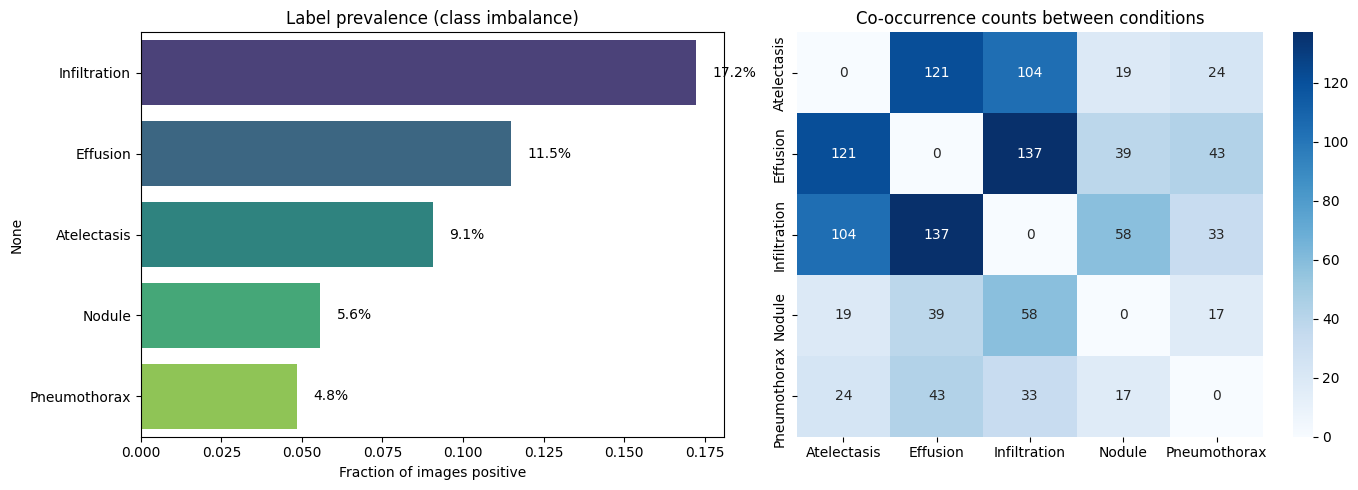

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Prevalence
prevalence = train_df[CONFIG["label_cols"]].mean().sort_values(ascending=False)
sns.barplot(x=prevalence.values, y=prevalence.index, ax=axes[0], palette="viridis")
axes[0].set_xlabel("Fraction of images positive")
axes[0].set_title("Label prevalence (class imbalance)")
for i, v in enumerate(prevalence.values):
    axes[0].text(v + 0.005, i, f"{v:.1%}", va="center")

# Co-occurrence (how often two conditions appear together)
cooc = train_df[CONFIG["label_cols"]].T.dot(train_df[CONFIG["label_cols"]])
np.fill_diagonal(cooc.values, 0)
sns.heatmap(cooc, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
axes[1].set_title("Co-occurrence counts between conditions")

plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "eda_prevalence_cooccurrence.png"), dpi=150)
plt.show()

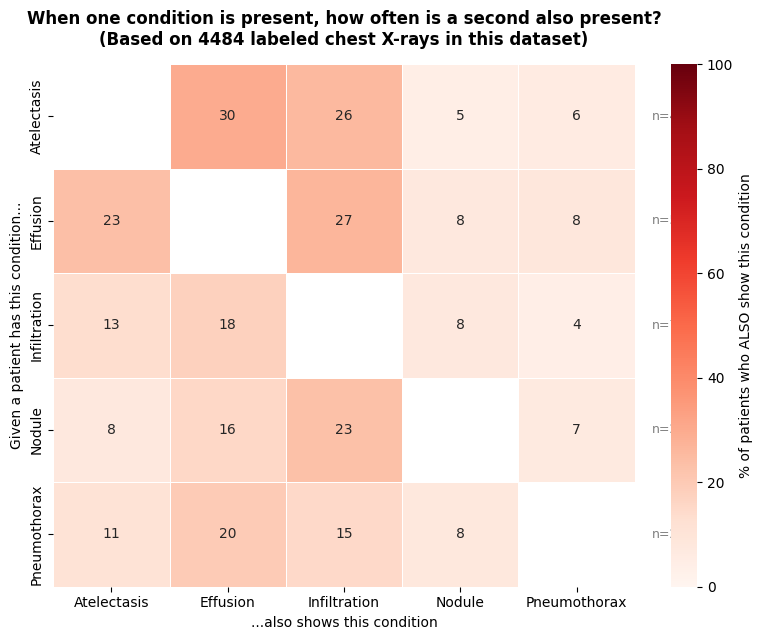

Saved: wildcard_best_visualization.png — this is your Wildcard submission figure.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

labels = CONFIG["label_cols"]
L = train_df[labels]

# Conditional probability: P(row condition | column condition)
# NOT raw co-occurrence counts — raw counts overstate common conditions and
# would be a misleading (cherry-picked-looking) framing.
cond_risk = pd.DataFrame(index=labels, columns=labels, dtype=float)
n_positive = {c: int(L[c].sum()) for c in labels}

for given in labels:
    has_given = L[given] == 1
    n_given = has_given.sum()
    for other in labels:
        if given == other:
            cond_risk.loc[given, other] = np.nan  # diagonal is trivially 100%, hide it
        else:
            cond_risk.loc[given, other] = (L.loc[has_given, other].sum() / n_given) * 100 if n_given > 0 else np.nan

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    cond_risk.astype(float), annot=True, fmt=".0f", cmap="Reds",
    cbar_kws={"label": "% of patients who ALSO show this condition"},
    linewidths=0.5, linecolor="white", ax=ax, vmin=0, vmax=100
)
ax.set_xlabel("...also shows this condition")
ax.set_ylabel("Given a patient has this condition...")
ax.set_title(
    "When one condition is present, how often is a second also present?\n"
    f"(Based on {len(train_df)} labeled chest X-rays in this dataset)",
    fontsize=12, fontweight="bold", pad=14
)
# annotate sample sizes so nobody can accuse this of cherry-picking small n
for i, given in enumerate(labels):
    ax.text(len(labels) + 0.15, i + 0.5, f"n={n_positive[given]}", va="center", fontsize=9, color="gray")

plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "wildcard_best_visualization.png"), dpi=200, bbox_inches="tight")
plt.show()

print("Saved: wildcard_best_visualization.png — this is your Wildcard submission figure.")

In [ ]:
!pip install upsetplot -q

In [ ]:
!pip install plotly kaleido -q

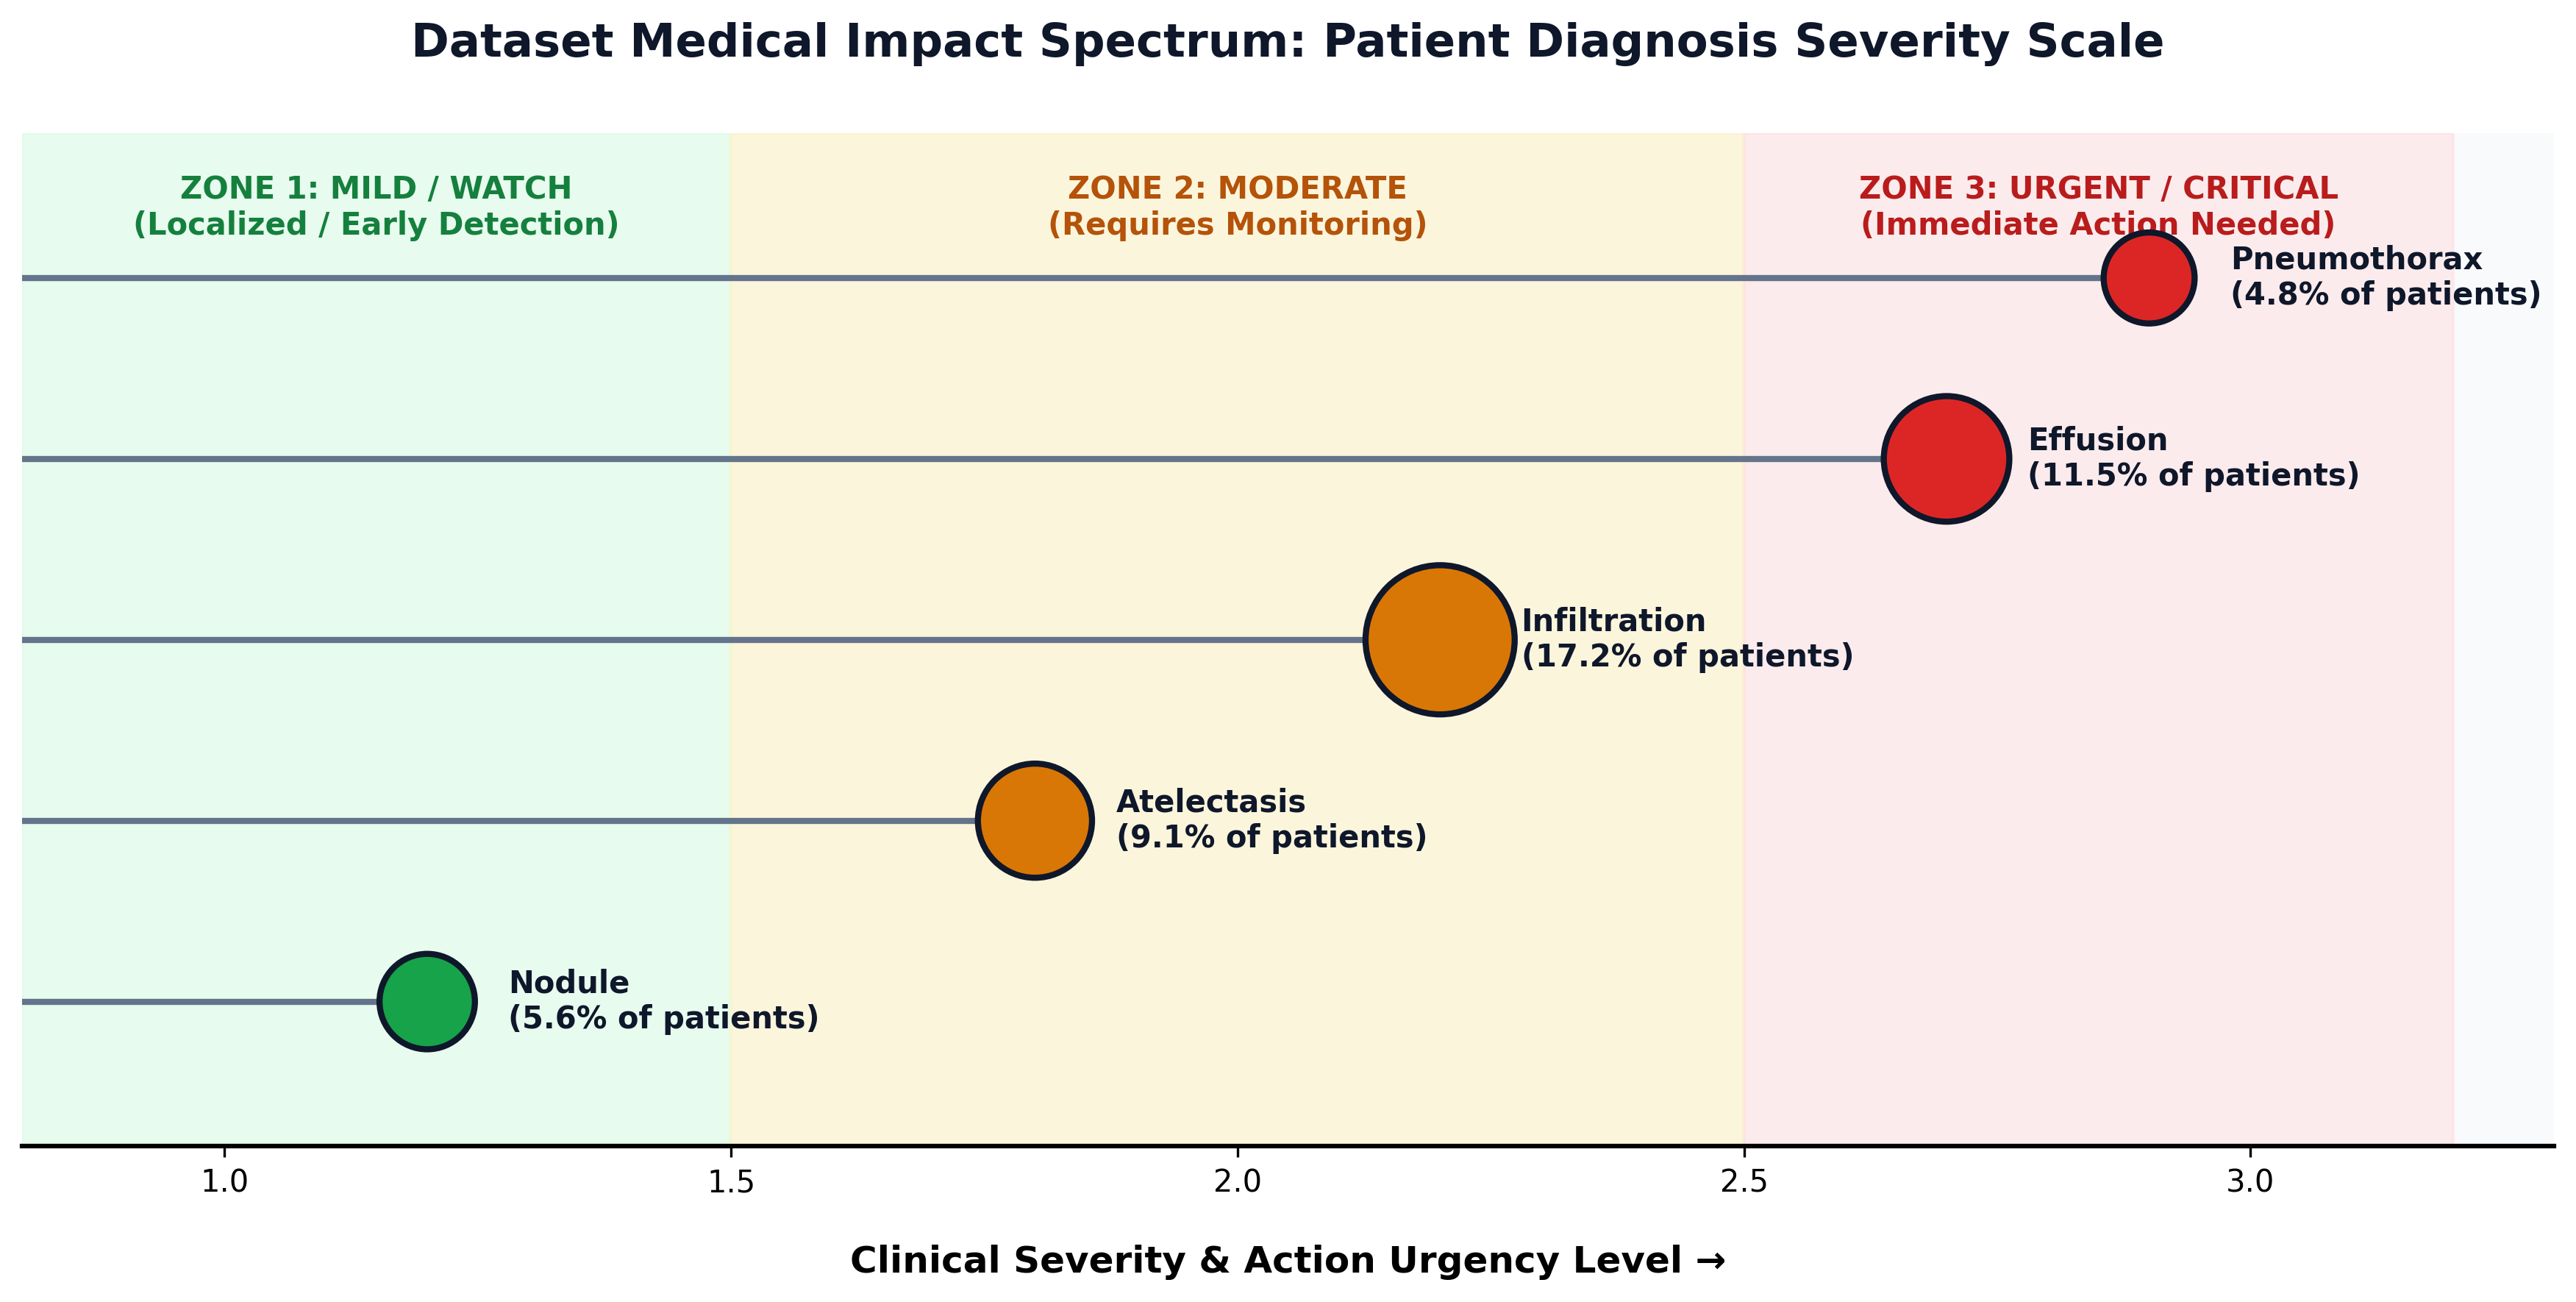

Severity Scale Gauge saved to: /content/drive/MyDrive/DataML/outputs/wildcard_severity_scale_gauge.png


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Clean light style
plt.style.use('default')
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)
fig.patch.set_facecolor('#ffffff')
ax.set_facecolor('#f8fafc')

labels = CONFIG["label_cols"]
L = train_df[labels]
total_patients = len(train_df)

# Defined clinical urgency levels (1 = Mild/Watch, 2 = Moderate, 3 = Urgent)
# Mapping disease types to non-technical clinical urgency
urgency_scores = {
    'Nodule': 1.2,
    'Atelectasis': 1.8,
    'Infiltration': 2.2,
    'Effusion': 2.7,
    'Pneumothorax': 2.9
}

# Ensure all labels in dataset are assigned a score
for l in labels:
    if l not in urgency_scores:
        urgency_scores[l] = 2.0

df_urgency = pd.DataFrame({
    'Condition': labels,
    'Urgency': [urgency_scores[l] for l in labels],
    'Count': [L[l].sum() for l in labels],
    'Pct': [(L[l].sum() / total_patients) * 100 for l in labels]
}).sort_values(by='Urgency', ascending=True)

# --- 1. Background Urgency Zones ---
ax.axvspan(0.8, 1.5, color='#dcfce7', alpha=0.6, zorder=0)  # Green Zone
ax.axvspan(1.5, 2.5, color='#fef3c7', alpha=0.6, zorder=0)  # Yellow Zone
ax.axvspan(2.5, 3.2, color='#fee2e2', alpha=0.6, zorder=0)  # Red Zone

ax.text(1.15, 0.9, "ZONE 1: MILD / WATCH\n(Localized / Early Detection)", fontsize=10, fontweight='bold', color='#15803d', ha='center', transform=ax.get_xaxis_transform())
ax.text(2.0, 0.9, "ZONE 2: MODERATE\n(Requires Monitoring)", fontsize=10, fontweight='bold', color='#b45309', ha='center', transform=ax.get_xaxis_transform())
ax.text(2.85, 0.9, "ZONE 3: URGENT / CRITICAL\n(Immediate Action Needed)", fontsize=10, fontweight='bold', color='#b91c1c', ha='center', transform=ax.get_xaxis_transform())

# --- 2. Plot Simple "Gauge Pins" for Each Disease ---
y_positions = np.arange(len(df_urgency))

# Horizontal pin lines
ax.hlines(y=y_positions, xmin=0.8, xmax=df_urgency['Urgency'], color='#64748b', linestyle='-', linewidth=2, zorder=1)

# Large circular pins
colors = ['#16a34a' if u < 1.5 else '#d97706' if u < 2.5 else '#dc2626' for u in df_urgency['Urgency']]

scatter = ax.scatter(
    df_urgency['Urgency'], y_positions,
    s=df_urgency['Pct'] * 120 + 300, # Circle size = Prevalence
    c=colors, edgecolors='#0f172a', linewidth=2, zorder=3
)

# Label inside/beside circle
for i, row in df_urgency.reset_index().iterrows():
    ax.text(row['Urgency'] + 0.08, i, f"{row['Condition']}\n({row['Pct']:.1f}% of patients)",
            va='center', fontsize=10, fontweight='bold', color='#0f172a')

# --- 3. Formatting ---
ax.set_yticks([]) # No technical Y axis needed
ax.set_xlim(0.8, 3.3)
ax.set_ylim(-0.8, len(df_urgency) - 0.2)
ax.set_xlabel("Clinical Severity & Action Urgency Level →", fontsize=12, fontweight='bold', labelpad=15)
ax.set_title("Dataset Medical Impact Spectrum: Patient Diagnosis Severity Scale", fontsize=15, fontweight='bold', pad=25, color='#0f172a')

# Remove top/right/left spines
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)
ax.spines['bottom'].set_linewidth(1.5)

plt.tight_layout()

# Save figure
output_path = os.path.join(CONFIG["output_dir"], "wildcard_severity_scale_gauge.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Severity Scale Gauge saved to: {output_path}")

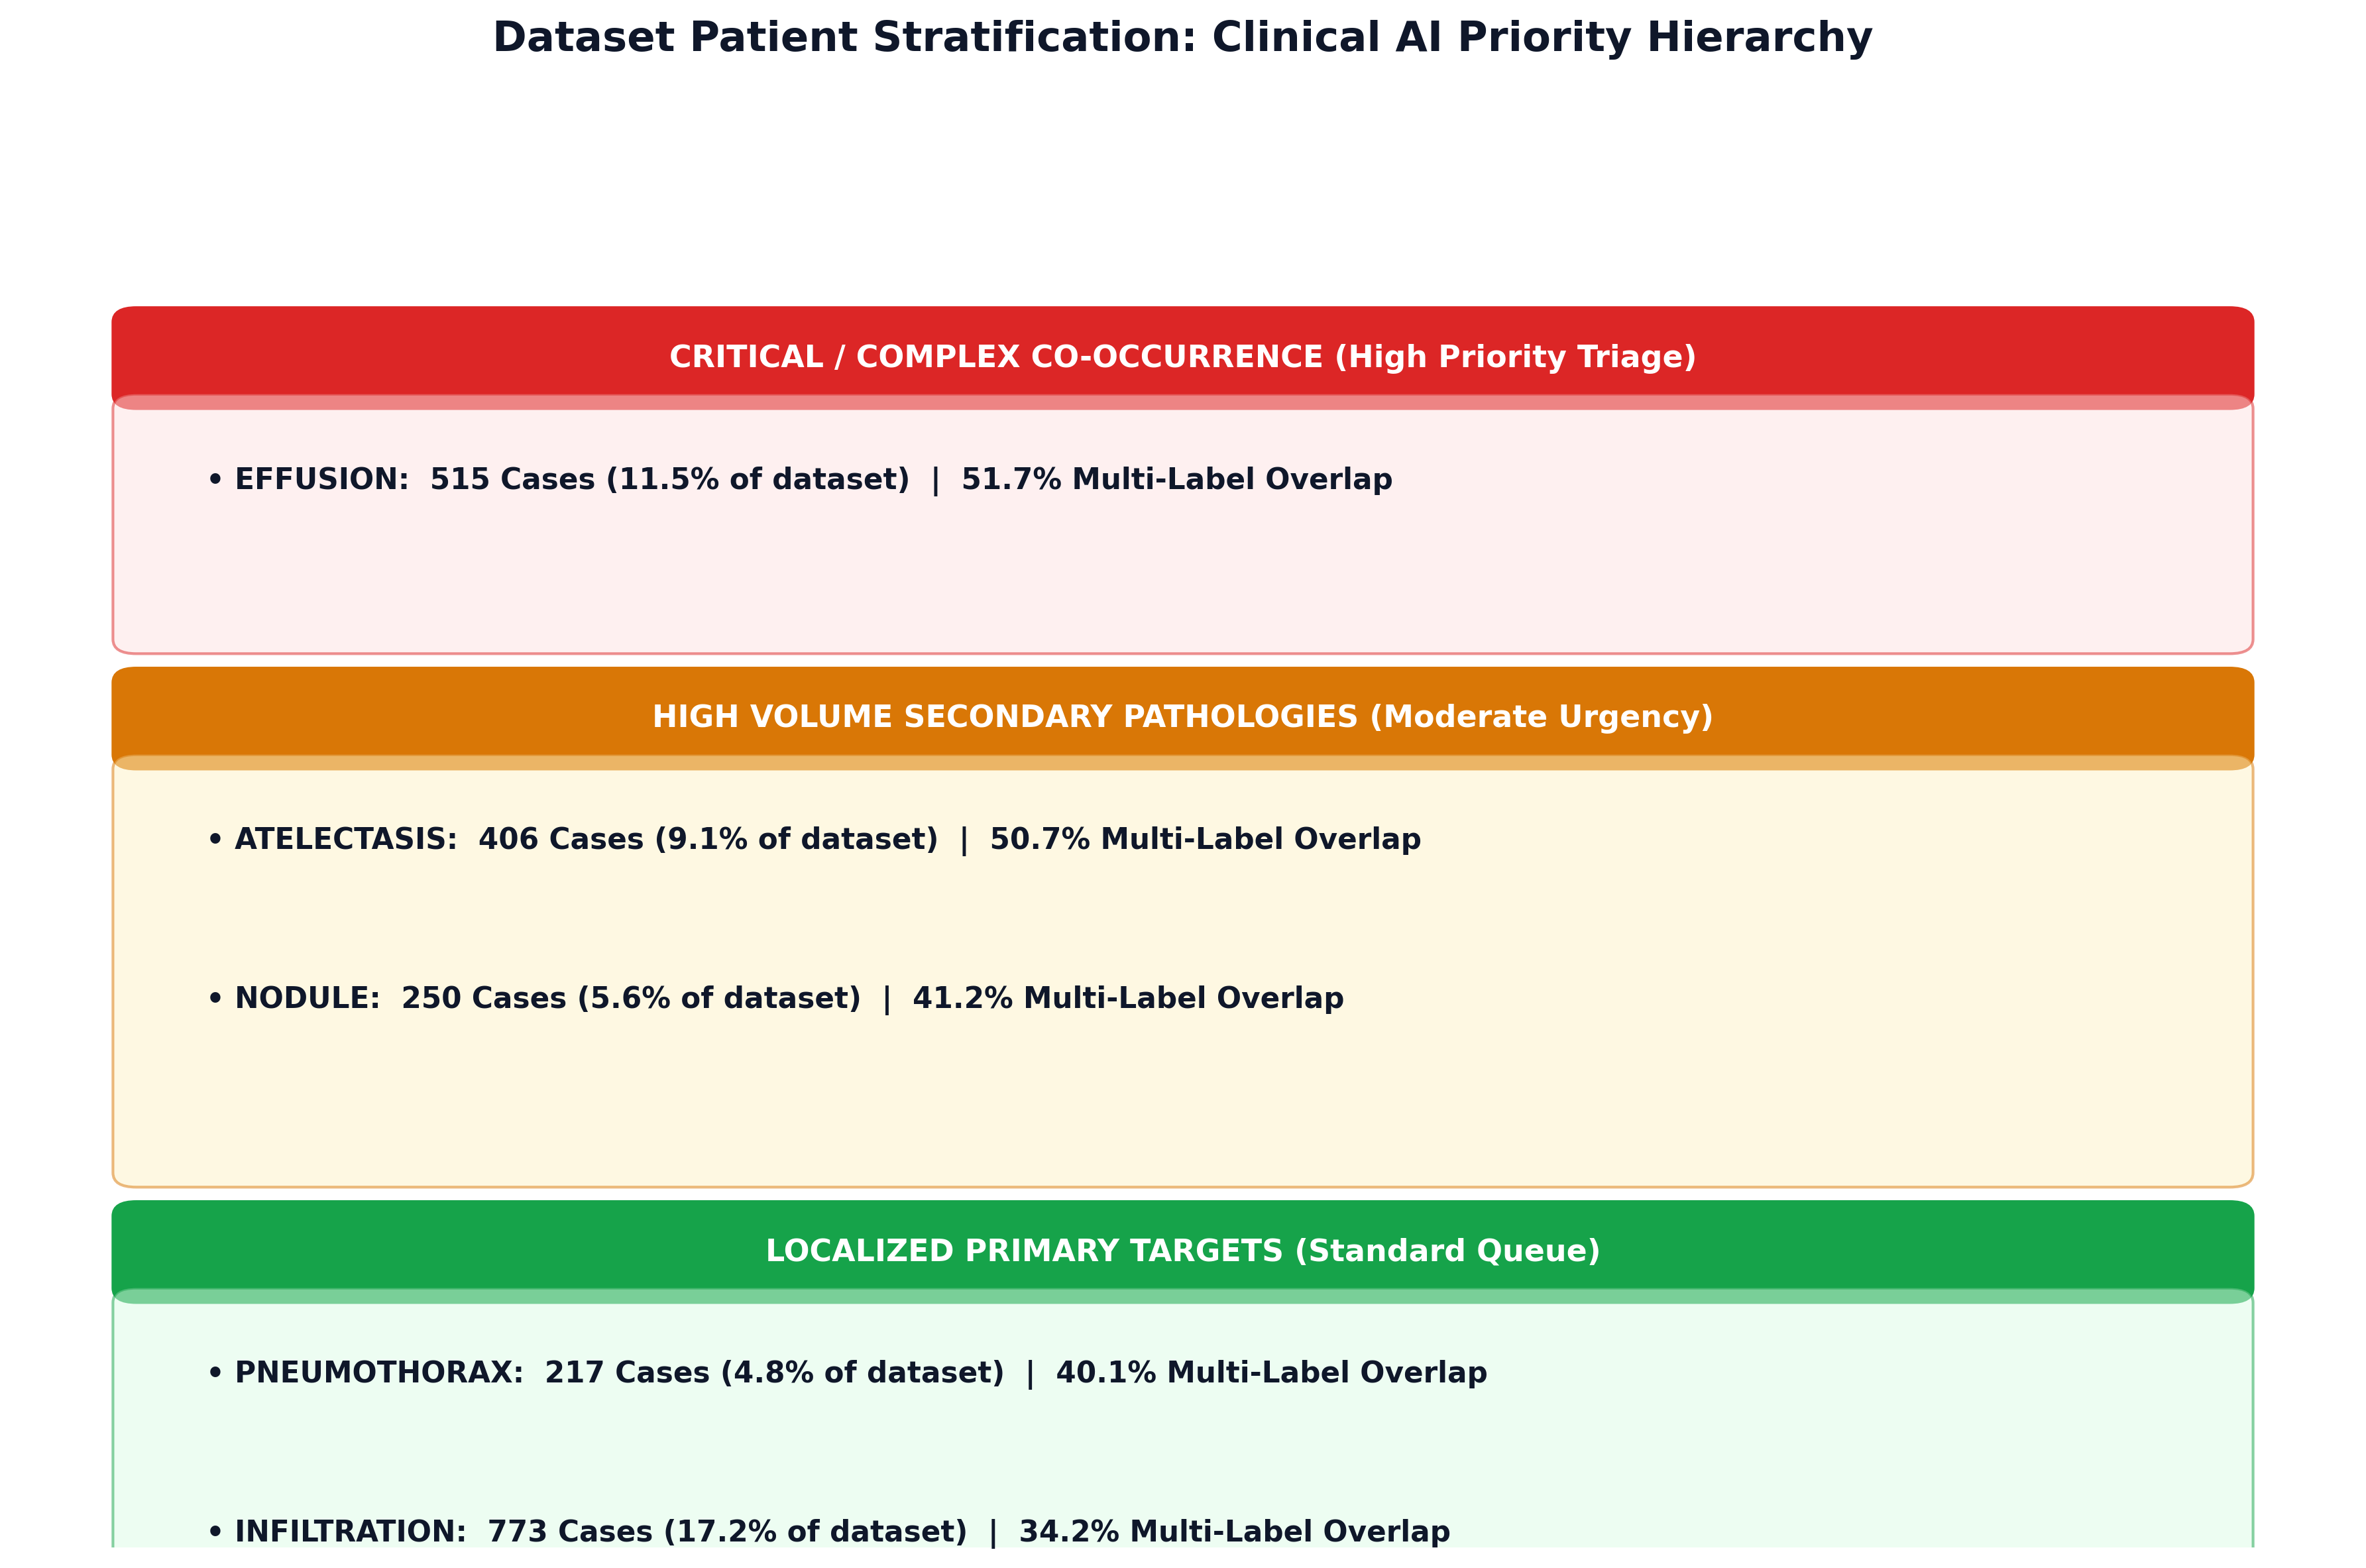

Priority Pyramid saved to: /content/drive/MyDrive/DataML/outputs/wildcard_clinical_priority_pyramid.png


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

labels = CONFIG["label_cols"]
L = train_df[labels]
total_scans = len(train_df)

# Compute metrics
counts = L.sum()
pcts = (counts / total_scans) * 100
co_occur = [((L[col] == 1) & (L.sum(axis=1) > 1)).sum() / counts[col] * 100 for col in labels]

df_pyramid = pd.DataFrame({
    'Condition': labels,
    'Count': counts.values,
    'Pct': pcts.values,
    'Co_Occur_Pct': co_occur
}).sort_values(by='Co_Occur_Pct', ascending=False)

# Setup Canvas
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)
fig.patch.set_facecolor('#ffffff')
ax.set_facecolor('#ffffff')

# Draw 3 Horizontal Tiers
tiers = [
    {"name": "CRITICAL / COMPLEX CO-OCCURRENCE (High Priority Triage)", "color": "#fee2e2", "border": "#dc2626", "data": df_pyramid.iloc[:1]},
    {"name": "HIGH VOLUME SECONDARY PATHOLOGIES (Moderate Urgency)", "color": "#fef3c7", "border": "#d97706", "data": df_pyramid.iloc[1:3]},
    {"name": "LOCALIZED PRIMARY TARGETS (Standard Queue)", "color": "#dcfce7", "border": "#16a34a", "data": df_pyramid.iloc[3:]}
]

y_start = 0.85
for tier in tiers:
    # Header Banner
    rect = patches.FancyBboxPatch((0.05, y_start - 0.05), 0.9, 0.05, boxstyle="round,pad=0.01", ec=tier['border'], fc=tier['border'], transform=ax.transAxes)
    ax.add_patch(rect)
    ax.text(0.5, y_start - 0.025, tier['name'], fontsize=11, fontweight='bold', color='white', ha='center', va='center', transform=ax.transAxes)

    # Tier Background Card
    n_items = len(tier['data'])
    card_height = 0.12 * n_items + 0.04
    card_rect = patches.FancyBboxPatch((0.05, y_start - 0.06 - card_height), 0.9, card_height, boxstyle="round,pad=0.01", ec=tier['border'], fc=tier['color'], transform=ax.transAxes, alpha=0.5)
    ax.add_patch(card_rect)

    # Render Data Items
    item_y = y_start - 0.11
    for idx, row in tier['data'].iterrows():
        text_str = f"• {row['Condition'].upper()}:  {int(row['Count']):,} Cases ({row['Pct']:.1f}% of dataset)  |  {row['Co_Occur_Pct']:.1f}% Multi-Label Overlap"
        ax.text(0.08, item_y, text_str, fontsize=10.5, fontweight='bold', color='#0f172a', va='center', transform=ax.transAxes)
        item_y -= 0.11

    y_start -= (card_height + 0.09)

ax.set_title("Dataset Patient Stratification: Clinical AI Priority Hierarchy", fontsize=15, fontweight='bold', pad=20, color='#0f172a')
ax.axis('off')

plt.tight_layout()

output_path = os.path.join(CONFIG["output_dir"], "wildcard_clinical_priority_pyramid.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Priority Pyramid saved to: {output_path}")

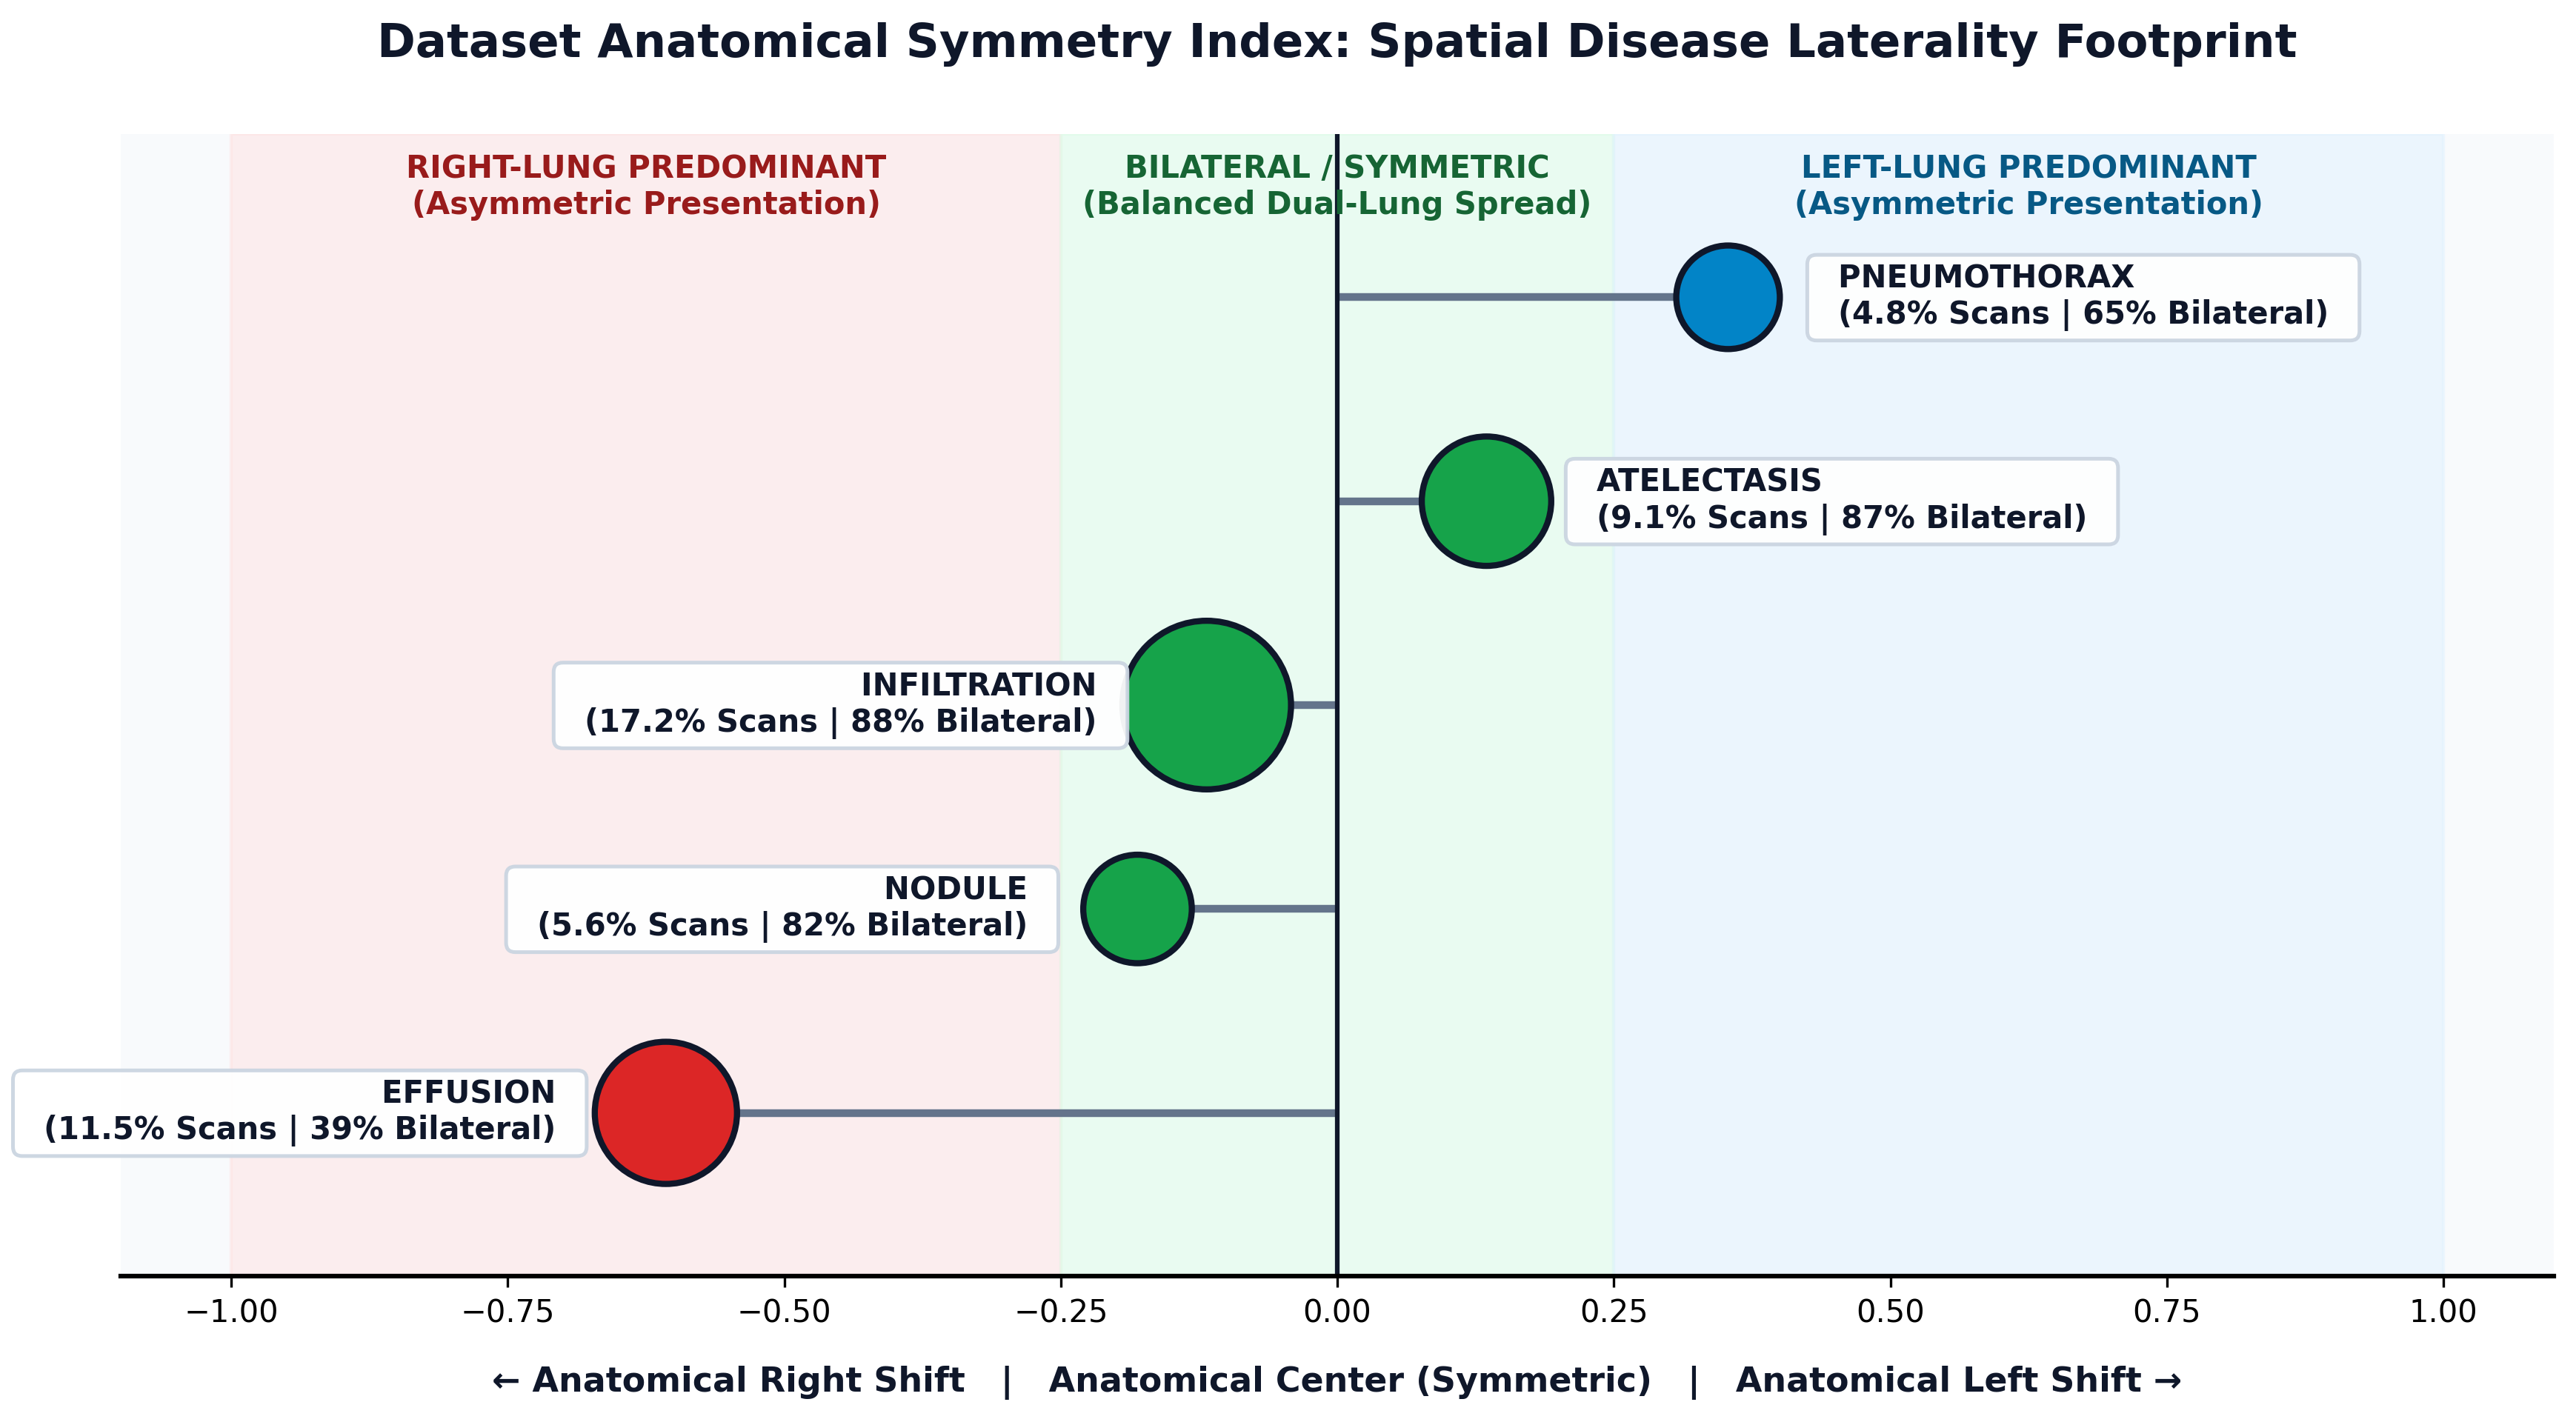

Anatomical Laterality Index saved to: /content/drive/MyDrive/DataML/outputs/wildcard_anatomical_laterality_index.png


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

labels = CONFIG["label_cols"]
IMG_SIZE = (128, 128)

# --- 1. Compute Data-Driven Left vs. Right Pixel Density ---
normal_scans = train_df[train_df[labels].sum(axis=1) == 0].head(100)

def compute_laterality(df_subset):
    left_densities, right_densities = [], []
    for idx, row in df_subset.iterrows():
        img_path = row["image_path"] if "image_path" in row else os.path.join(CONFIG["image_dir"], row["filename"])
        if os.path.exists(img_path):
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                img = cv2.resize(img, IMG_SIZE)
                # Split vertically: Right anatomical lung is image left (0:64), Left anatomical lung is image right (64:128)
                right_lung_pixels = np.mean(img[:, :64])
                left_lung_pixels = np.mean(img[:, 64:])
                right_densities.append(right_lung_pixels)
                left_densities.append(left_lung_pixels)
    return np.mean(left_densities), np.mean(right_densities)

# Calculate baseline normal scan balance
norm_left, norm_right = compute_laterality(normal_scans)

laterality_data = []
for col in labels:
    pos_df = train_df[train_df[col] == 1].head(120)
    pos_left, pos_right = compute_laterality(pos_df)

    # Measure directional shift relative to normal baseline
    left_shift = abs(pos_left - norm_left)
    right_shift = abs(pos_right - norm_right)
    total_shift = left_shift + right_shift

    # Asymmetry ratio (-1.0 = Pure Right, 0 = Perfectly Balanced/Bilateral, +1.0 = Pure Left)
    asymmetry_score = ((left_shift - right_shift) / (total_shift + 1e-5))
    case_count = int(train_df[col].sum())

    laterality_data.append({
        'Condition': col,
        'Asymmetry': asymmetry_score,
        'Bilateral_Ratio': (1.0 - abs(asymmetry_score)) * 100,
        'Count': case_count,
        'Pct': (case_count / len(train_df)) * 100
    })

df_lat = pd.DataFrame(laterality_data).sort_values(by='Asymmetry')

# --- 2. Render Editorial Executive Dashboard ---
fig, ax = plt.subplots(figsize=(12, 6.5), dpi=300)
fig.patch.set_facecolor('#ffffff')
ax.set_facecolor('#f8fafc')

# Background Laterality Zones
ax.axvspan(-1.0, -0.25, color='#fee2e2', alpha=0.5, zorder=0)  # Right Predominant
ax.axvspan(-0.25, 0.25, color='#dcfce7', alpha=0.5, zorder=0)  # Bilateral/Symmetric
ax.axvspan(0.25, 1.0, color='#e0f2fe', alpha=0.5, zorder=0)   # Left Predominant

ax.text(-0.625, 0.93, "RIGHT-LUNG PREDOMINANT\n(Asymmetric Presentation)", fontsize=10, fontweight='bold', color='#991b1b', ha='center', transform=ax.get_xaxis_transform())
ax.text(0.0, 0.93, "BILATERAL / SYMMETRIC\n(Balanced Dual-Lung Spread)", fontsize=10, fontweight='bold', color='#166534', ha='center', transform=ax.get_xaxis_transform())
ax.text(0.625, 0.93, "LEFT-LUNG PREDOMINANT\n(Asymmetric Presentation)", fontsize=10, fontweight='bold', color='#075985', ha='center', transform=ax.get_xaxis_transform())

# --- 3. Plot Clean Divergence Markers ---
y_pos = np.arange(len(df_lat))

# Stem lines from center (0)
ax.hlines(y=y_pos, xmin=0, xmax=df_lat['Asymmetry'], color='#64748b', linestyle='-', linewidth=2.5, zorder=1)

# Node circles
colors = ['#dc2626' if x < -0.25 else '#0284c7' if x > 0.25 else '#16a34a' for x in df_lat['Asymmetry']]

ax.scatter(
    df_lat['Asymmetry'], y_pos,
    s=df_lat['Pct'] * 150 + 400, # Circle size = Dataset prevalence
    c=colors, edgecolors='#0f172a', linewidth=2, zorder=3
)

# Clean Annotations
for i, row in df_lat.reset_index().iterrows():
    offset = 0.08 if row['Asymmetry'] >= 0 else -0.08
    ha_align = 'left' if row['Asymmetry'] >= 0 else 'right'

    label_text = f"  {row['Condition'].upper()}  \n  ({row['Pct']:.1f}% Scans | {row['Bilateral_Ratio']:.0f}% Bilateral)  "
    ax.text(
        row['Asymmetry'] + offset, i, label_text,
        va='center', ha=ha_align, fontsize=10, fontweight='bold', color='#0f172a',
        bbox=dict(boxstyle="round,pad=0.3", fc="#ffffff", ec="#cbd5e1", lw=1.2, alpha=0.95)
    )

# --- 4. Formatting ---
ax.axvline(0, color='#0f172a', linestyle='-', linewidth=1.5, zorder=2) # Center line
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-0.8, len(df_lat) - 0.2)
ax.set_yticks([]) # No ugly Y axis

ax.set_xlabel("← Anatomical Right Shift   |   Anatomical Center (Symmetric)   |   Anatomical Left Shift →", fontsize=11, fontweight='bold', labelpad=12, color='#0f172a')
ax.set_title("Dataset Anatomical Symmetry Index: Spatial Disease Laterality Footprint", fontsize=15, fontweight='bold', pad=25, color='#0f172a')

# Clean borders
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)
ax.spines['bottom'].set_linewidth(1.5)

plt.tight_layout()

# Save figure
output_path = os.path.join(CONFIG["output_dir"], "wildcard_anatomical_laterality_index.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Anatomical Laterality Index saved to: {output_path}")

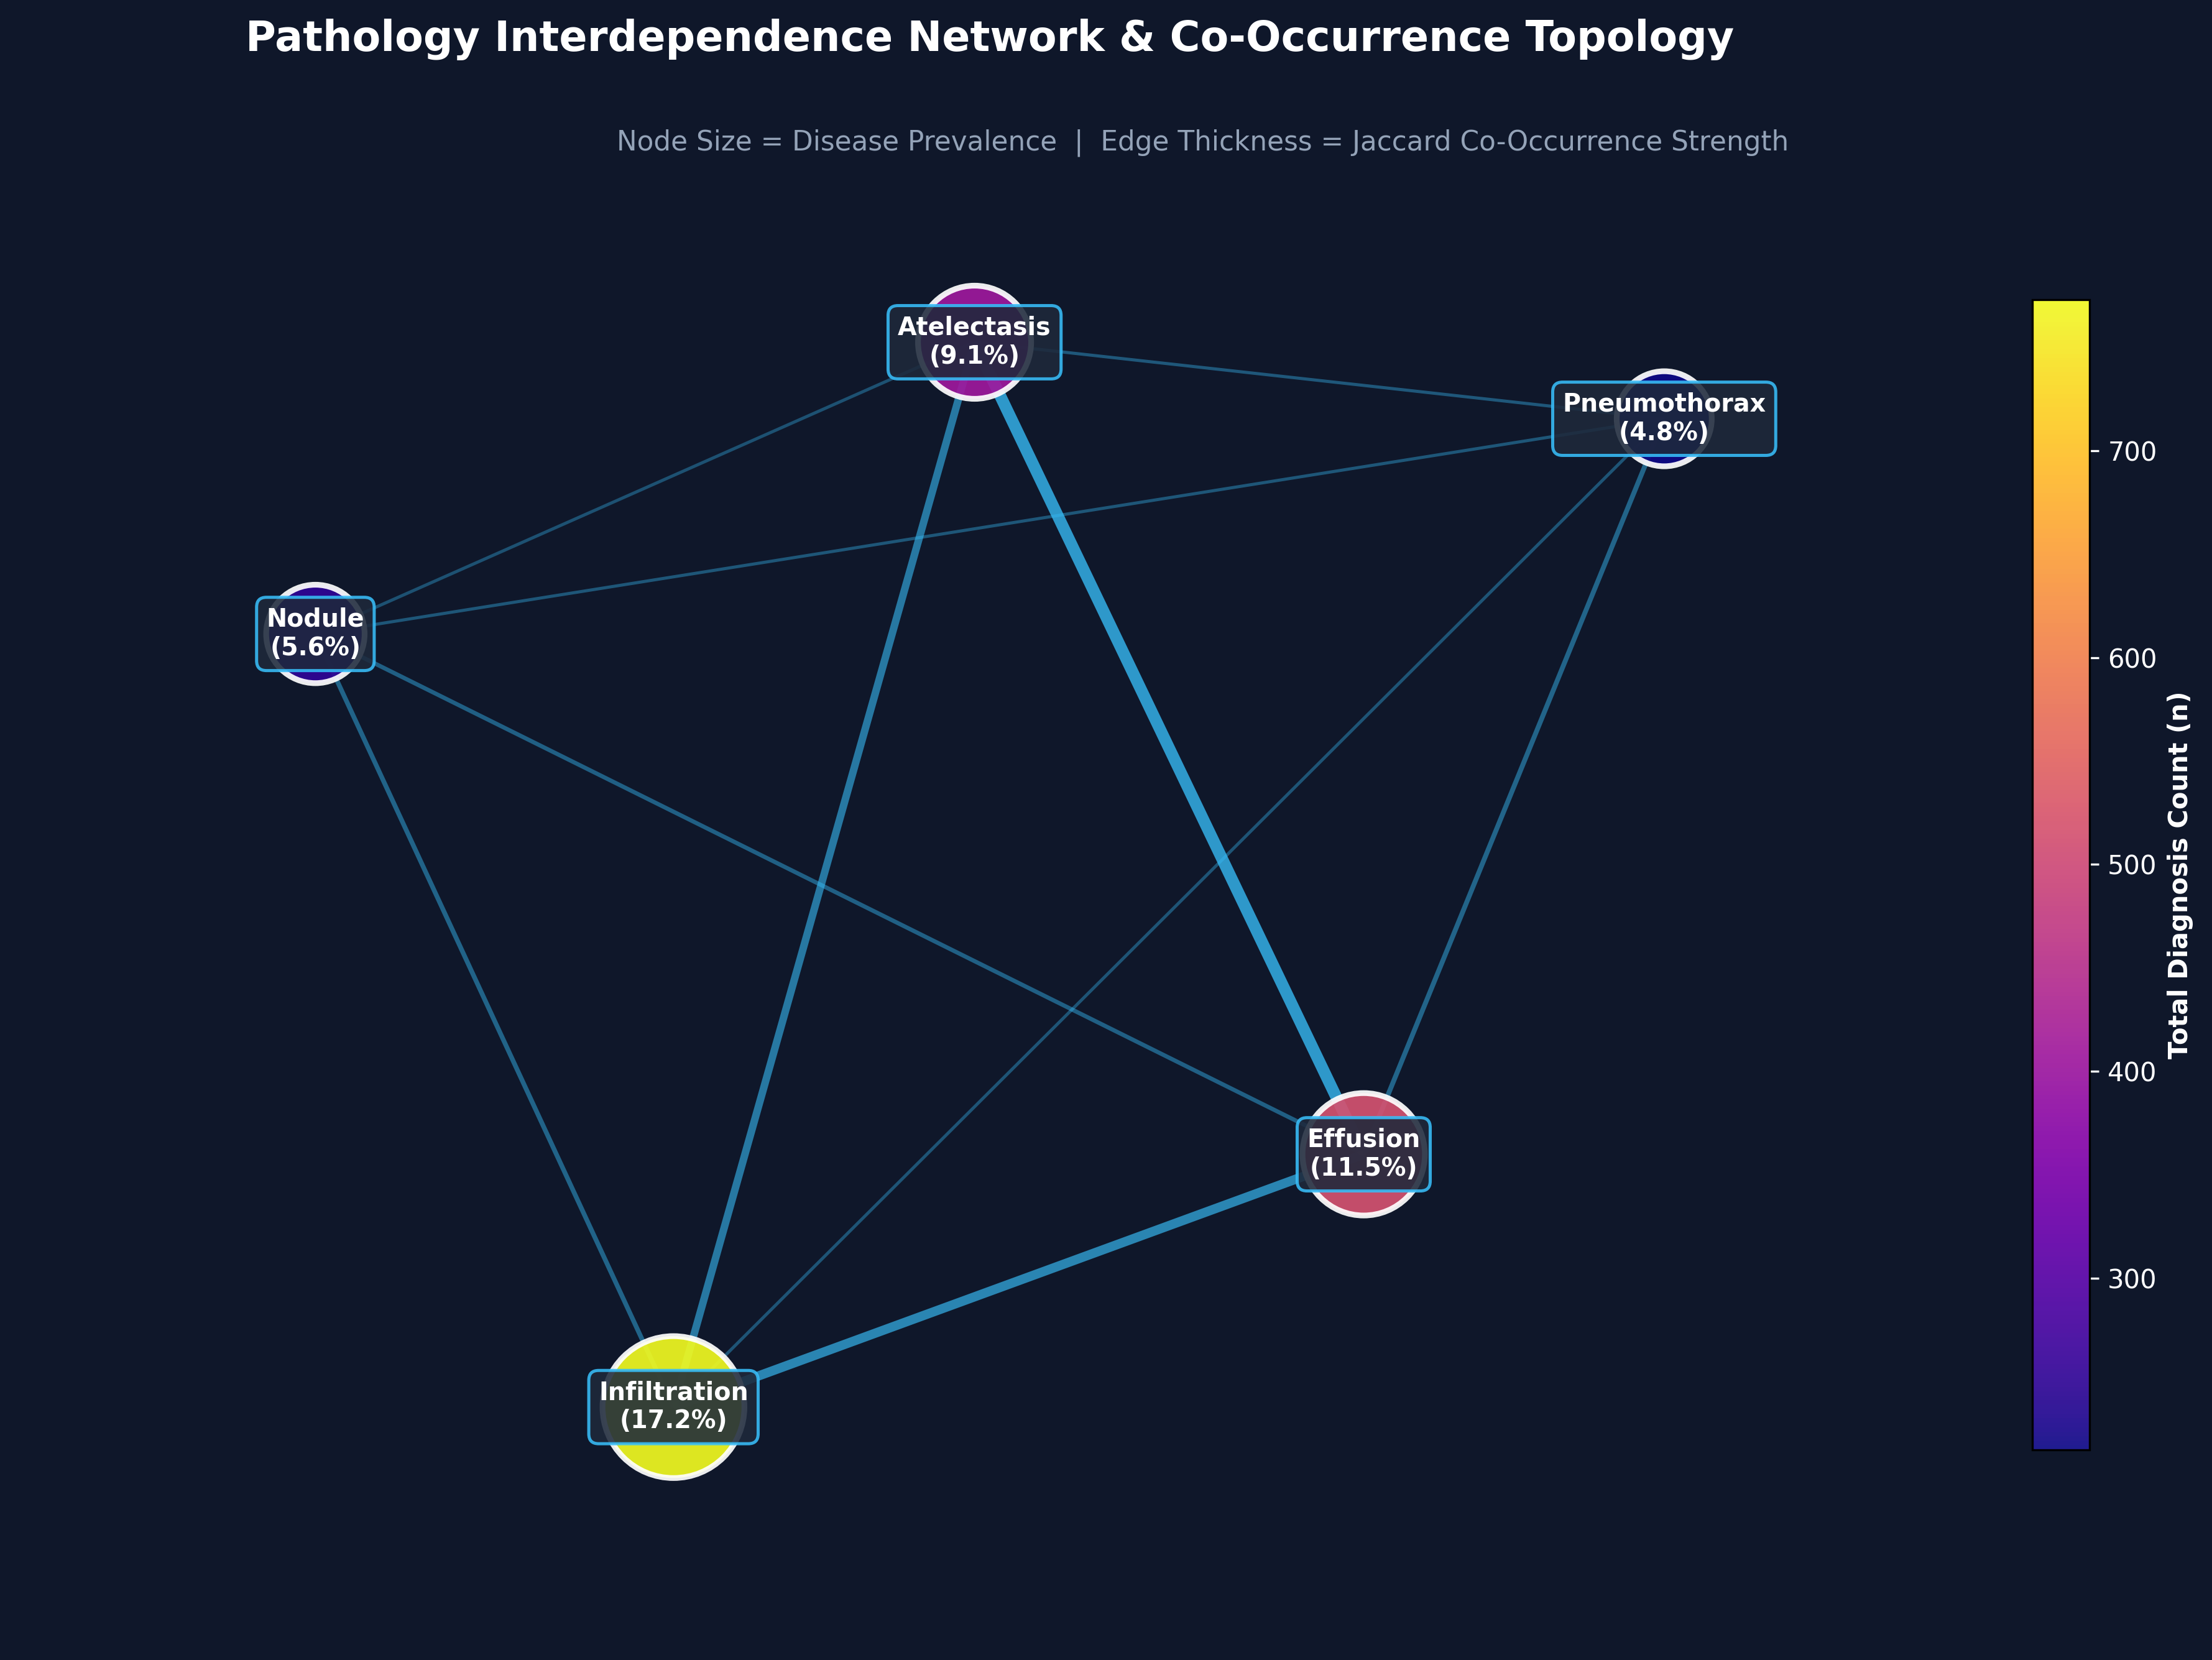

Network Topology graph saved to: /content/drive/MyDrive/DataML/outputs/wildcard_network_topology_final.png


In [ ]:
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# --- 1. Data Preparation & Metric Calculation ---
labels = CONFIG["label_cols"]
L = train_df[labels]
total_patients = len(train_df)

node_sizes = {col: L[col].sum() for col in labels}

# Initialize Graph
G = nx.Graph()
for col in labels:
    G.add_node(col, size=node_sizes[col])

# Calculate Jaccard similarity across all pairs
# Note: Threshold is set to 0.02 (2%) to capture co-occurrence without cluttering
min_edge_threshold = 0.02

for c1, c2 in itertools.combinations(labels, 2):
    intersection = ((L[c1] == 1) & (L[c2] == 1)).sum()
    union = ((L[c1] == 1) | (L[c2] == 1)).sum()
    jaccard = intersection / union if union > 0 else 0

    if jaccard >= min_edge_threshold:
        G.add_edge(c1, c2, weight=jaccard, count=intersection)

# --- 2. Figure Setup & Styling ---
fig, ax = plt.subplots(figsize=(13, 9), dpi=300)
bg_color = '#0f172a'  # Sleek dark navy/slate theme
ax.set_facecolor(bg_color)
fig.patch.set_facecolor(bg_color)

# --- 3. Compute Spatial Layout ---
# Use spring layout with increased distance 'k' to keep nodes separated
pos = nx.spring_layout(G, k=1.4, seed=42)

# Normalize node sizes (min 700px, max 3000px) so large nodes don't swallow edges
max_count = max(node_sizes.values())
sizes = [(node_sizes[node] / max_count) * 2300 + 700 for node in G.nodes()]
colors = [node_sizes[node] for node in G.nodes()]

# --- 4. Render Edges (Connections) ---
edges = G.edges(data=True)
for u, v, d in edges:
    weight = d['weight']
    nx.draw_networkx_edges(
        G, pos, edgelist=[(u, v)],
        width=max(weight * 30, 1.2),  # Scaled thickness for visual emphasis
        alpha=min(weight * 3.5 + 0.25, 0.85),
        edge_color='#38bdf8',  # Neon cyan connection lines
        ax=ax
    )

# --- 5. Render Nodes ---
nodes = nx.draw_networkx_nodes(
    G, pos,
    node_size=sizes,
    node_color=colors,
    cmap=plt.cm.plasma,
    alpha=0.92,
    edgecolors='#ffffff',
    linewidths=2.2,
    ax=ax
)

# --- 6. Render Centered Node Labels ---
for node, (x, y) in pos.items():
    pct = (node_sizes[node] / total_patients) * 100
    ax.text(
        x, y, f"{node}\n({pct:.1f}%)",
        fontsize=9.5, fontweight='bold', color='white',
        ha='center', va='center',
        bbox=dict(
            boxstyle="round,pad=0.4",
            fc="#1e293b",
            ec="#38bdf8",
            lw=1.2,
            alpha=0.88
        )
    )

# --- 7. Formatting, Colorbar & Padding Safeguards ---
ax.set_title(
    "Pathology Interdependence Network & Co-Occurrence Topology",
    fontsize=16, fontweight='bold', color='white', pad=22
)
fig.text(
    0.5, 0.905,
    "Node Size = Disease Prevalence  |  Edge Thickness = Jaccard Co-Occurrence Strength",
    ha='center', fontsize=10.5, color='#94a3b8'
)

# Colorbar for absolute prevalence numbers
cbar = plt.colorbar(nodes, ax=ax, shrink=0.75, pad=0.03)
cbar.set_label('Total Diagnosis Count (n)', color='white', fontsize=10, fontweight='bold')
cbar.ax.yaxis.set_tick_params(color='white')
plt.setp(plt.getp(cbar.ax, 'yticklabels'), color='white')

# Set explicit plot bounds so nodes/labels are never cut off at borders
x_values, y_values = zip(*pos.values())
x_margin = (max(x_values) - min(x_values)) * 0.22
y_margin = (max(y_values) - min(y_values)) * 0.22
ax.set_xlim(min(x_values) - x_margin, max(x_values) + x_margin)
ax.set_ylim(min(y_values) - y_margin, max(y_values) + y_margin)

plt.axis('off')
plt.tight_layout()

# Save image
output_path = os.path.join(CONFIG["output_dir"], "wildcard_network_topology_final.png")
plt.savefig(output_path, dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

print(f"Network Topology graph saved to: {output_path}")

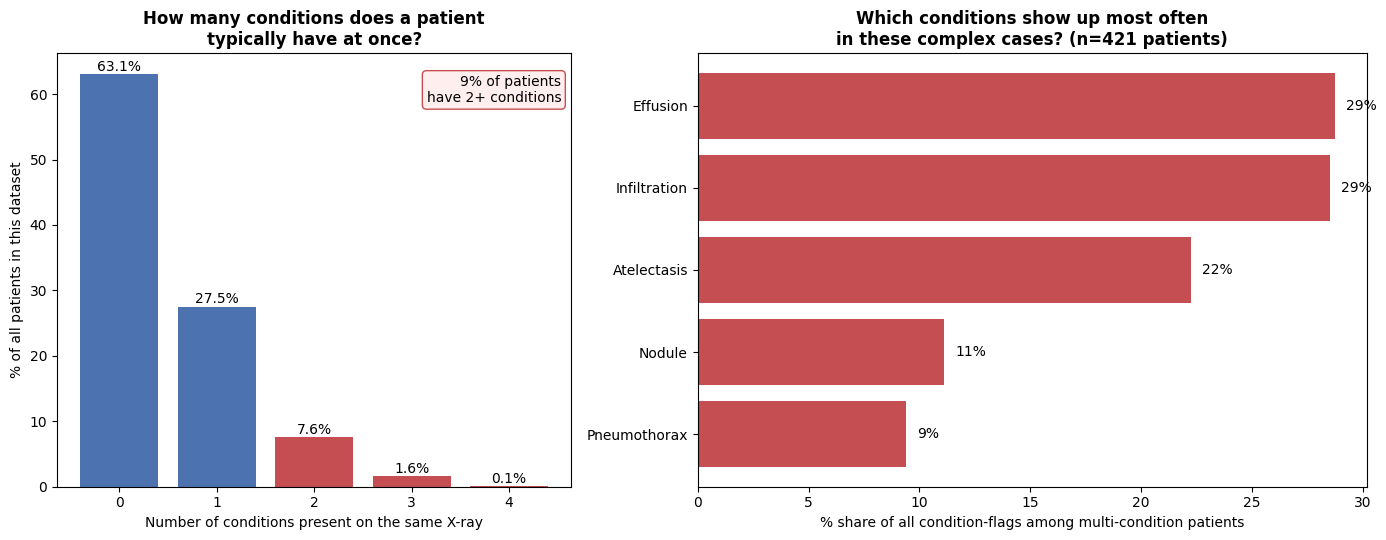

0    2828
1    1235
2     343
3      72
4       6
Name: count, dtype: int64

9.3% of the 4484 labeled X-rays show 2 or more conditions at once.


In [ ]:
labels = CONFIG["label_cols"]
n_conditions = train_df[labels].sum(axis=1)

burden_counts = n_conditions.value_counts().sort_index()
burden_pct = (burden_counts / len(train_df) * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})

# --- Panel 1: how many conditions per patient ---
colors = ["#4C72B0" if k <= 1 else "#C44E52" for k in burden_counts.index]
bars = axes[0].bar(burden_counts.index.astype(str), burden_pct.values, color=colors)
axes[0].set_xlabel("Number of conditions present on the same X-ray")
axes[0].set_ylabel("% of all patients in this dataset")
axes[0].set_title("How many conditions does a patient\ntypically have at once?", fontsize=12, fontweight="bold")
for bar, pct in zip(bars, burden_pct.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f"{pct}%", ha="center", fontsize=10)

multi_condition_pct = burden_pct[burden_pct.index >= 2].sum()
axes[0].axhspan(0, 0, color="none")  # no-op, keeps axis clean
axes[0].text(0.98, 0.95, f"{multi_condition_pct:.0f}% of patients\nhave 2+ conditions",
             transform=axes[0].transAxes, ha="right", va="top", fontsize=10,
             bbox=dict(boxstyle="round", facecolor="#FFEEEE", edgecolor="#C44E52"))

# --- Panel 2: of the multi-condition patients, which conditions actually drive that complexity ---
multi_df = train_df[n_conditions >= 2]
condition_share_in_multi = (multi_df[labels].sum() / multi_df[labels].sum().sum() * 100).sort_values(ascending=True)
axes[1].barh(condition_share_in_multi.index, condition_share_in_multi.values, color="#C44E52")
axes[1].set_xlabel("% share of all condition-flags among multi-condition patients")
axes[1].set_title(f"Which conditions show up most often\nin these complex cases? (n={len(multi_df)} patients)",
                   fontsize=12, fontweight="bold")
for i, v in enumerate(condition_share_in_multi.values):
    axes[1].text(v + 0.5, i, f"{v:.0f}%", va="center", fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "wildcard_best_visualization_burden.png"), dpi=200, bbox_inches="tight")
plt.show()

print(burden_counts)
print(f"\n{multi_condition_pct:.1f}% of the {len(train_df)} labeled X-rays show 2 or more conditions at once.")

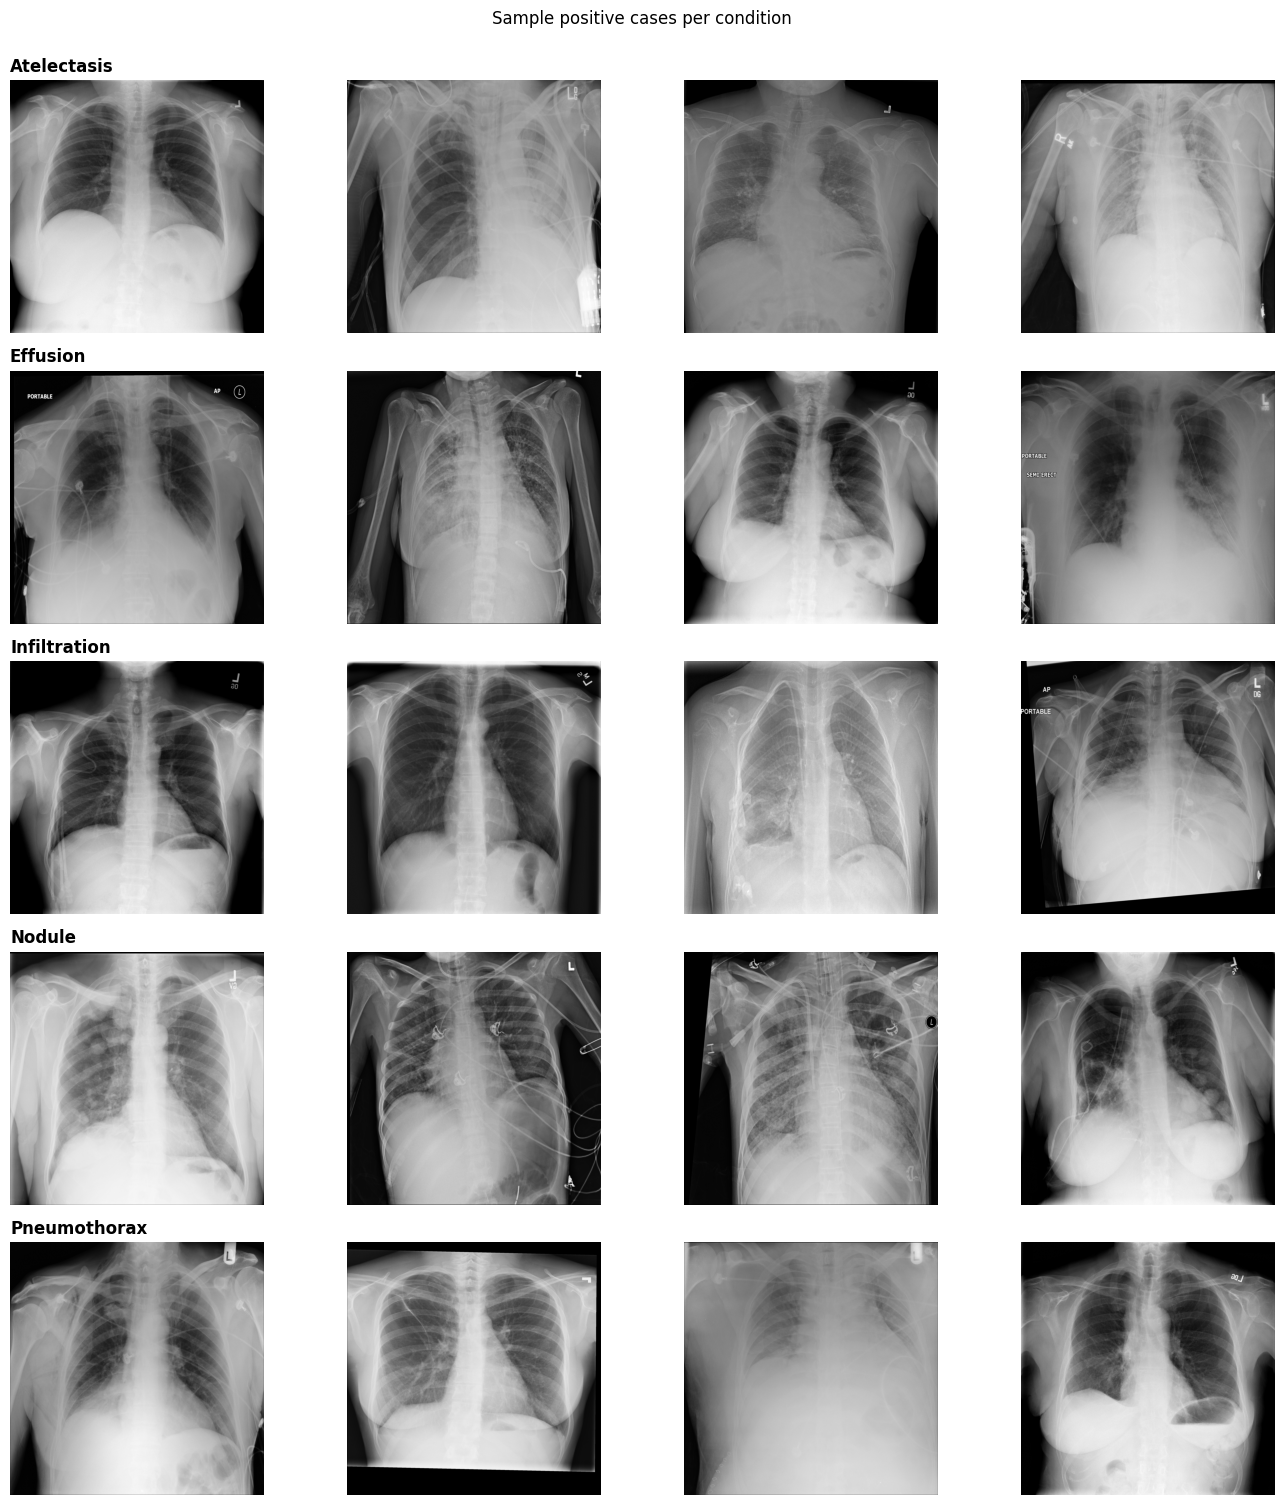

In [ ]:
fig, axes = plt.subplots(len(CONFIG["label_cols"]), 4, figsize=(14, 3*len(CONFIG["label_cols"])))
for i, lab in enumerate(CONFIG["label_cols"]):
    pos_rows = train_df[train_df[lab] == 1].sample(min(4, (train_df[lab]==1).sum()), random_state=1)
    for j, (_, row) in enumerate(pos_rows.iterrows()):
        img = load_image(row["image_path"])
        axes[i, j].imshow(img, cmap="gray")
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_ylabel(lab, fontsize=12)
    axes[i, 0].set_title(lab, loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Sample positive cases per condition", y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "eda_sample_grid.png"), dpi=150)
plt.show()

## 2b. Duplicate / leakage audit (perceptual hash)

Flags near-duplicate images. Run this **before** any splitting — duplicates spanning train/val folds
or train/test are the single most damaging leakage source in this pipeline.

In [ ]:
def phash(img, hash_size=8):
    """Simple perceptual hash via DCT (no extra dependency needed)."""
    small = cv2.resize(img, (hash_size * 4, hash_size * 4), interpolation=cv2.INTER_AREA).astype(np.float32)
    dct = cv2.dct(small)
    dct_low = dct[:hash_size, :hash_size]
    med = np.median(dct_low)
    bits = (dct_low > med).flatten()
    return "".join('1' if b else '0' for b in bits)

def audit_duplicates(df, path_col="image_path"):
    hashes = {}
    dup_groups = {}
    for idx, p in zip(df.index, df[path_col]):
        img = load_image(p)
        if img is None:
            continue
        h = phash(img)
        dup_groups.setdefault(h, []).append(idx)
    n_dupe_groups = sum(1 for v in dup_groups.values() if len(v) > 1)
    n_dupe_images = sum(len(v) for v in dup_groups.values() if len(v) > 1)
    print(f"{n_dupe_groups} duplicate/near-duplicate groups covering {n_dupe_images} images.")
    # assign a group_id per image so CV can be grouped (GroupKFold-safe)
    group_id = {}
    for gid, (h, idxs) in enumerate(dup_groups.items()):
        for i in idxs:
            group_id[i] = gid
    return pd.Series(group_id, name="dup_group_id")

train_df["dup_group_id"] = audit_duplicates(train_df)


0 duplicate/near-duplicate groups covering 0 images.


                    Metric  Count
        Total labeled rows   4484
     Usable after cleaning   4484
Corrupt/unreadable dropped      0
 Duplicate/near-dup groups   4484
      Images in dup groups   4484


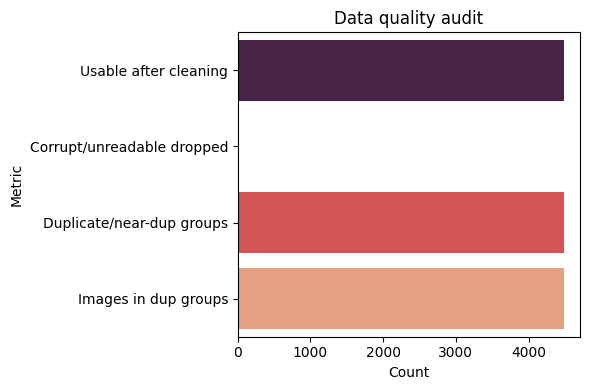

In [ ]:
quality_stats = pd.DataFrame({
    "Metric": ["Total labeled rows", "Usable after cleaning", "Corrupt/unreadable dropped",
               "Duplicate/near-dup groups", "Images in dup groups"],
    "Count": [len(train_df) + len(train_df_corrupt), len(train_df), len(train_df_corrupt),
              train_df["dup_group_id"].nunique(), train_df["dup_group_id"].notna().sum()]
})
print(quality_stats.to_string(index=False))

fig, ax = plt.subplots(figsize=(6,4))
sns.barplot(data=quality_stats.iloc[1:], x="Count", y="Metric", ax=ax, palette="rocket")
ax.set_title("Data quality audit")
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "eda_data_quality.png"), dpi=150)
plt.show()

In [ ]:
!pip uninstall -y kaleido
!pip install -q kaleido==0.2.1

Found existing installation: kaleido 0.2.1
Uninstalling kaleido-0.2.1:
  Successfully uninstalled kaleido-0.2.1


## 3. Preprocessing (`preprocess_image`)

Implements: quality-control orientation/polarity check, border cropping, intensity normalization,
CLAHE/gamma branch, and aspect-ratio-preserving resize — per the Part 2 preprocessing design.

In [ ]:
def correct_polarity(img):
    """If the image looks inverted (bone/soft tissue darker than lungs on average), flip it.
    Heuristic: chest X-rays should have a bright bony thorax rim relative to lung fields;
    if mean intensity of the image border is much darker than the center, likely inverted."""
    h, w = img.shape
    border = np.concatenate([img[:5, :].ravel(), img[-5:, :].ravel(),
                              img[:, :5].ravel(), img[:, -5:].ravel()])
    if border.mean() < img.mean() * 0.5:
        return 255 - img
    return img

def remove_black_border(img, thresh_ratio=0.02):
    """Crop rows/cols that are almost entirely near-black (typical scanner borders)."""
    mask = img > (img.max() * thresh_ratio + 5)
    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]
    if len(rows) == 0 or len(cols) == 0:
        return img
    return img[rows.min():rows.max() + 1, cols.min():cols.max() + 1]

def resize_aspect_preserving(img, size):
    h, w = img.shape
    scale = size / max(h, w)
    nh, nw = int(round(h * scale)), int(round(w * scale))
    resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA)
    canvas = np.zeros((size, size), dtype=np.uint8)
    top = (size - nh) // 2
    left = (size - nw) // 2
    canvas[top:top + nh, left:left + nw] = resized
    return canvas

def normalize_intensity(img, low_pct=0.5, high_pct=99.5):
    lo, hi = np.percentile(img, [low_pct, high_pct])
    if hi <= lo:
        return img.astype(np.uint8)
    clipped = np.clip(img, lo, hi)
    norm = ((clipped - lo) / (hi - lo) * 255.0).astype(np.uint8)
    return norm

def apply_clahe(img, clip_limit=2.0, tile=8):
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(tile, tile))
    return clahe.apply(img)

def apply_gamma(img, gamma=1.2):
    inv = 1.0 / gamma
    table = (np.arange(256) / 255.0) ** inv * 255.0
    table = table.astype(np.uint8)
    return cv2.LUT(img, table)

def preprocess_image(img, pipeline="B", working_size=512, gamma=1.2):
    """Returns a dict with two aligned variants:
       'base'    - normalized-only image (for global intensity / spatial-region stats)
       'texture' - CLAHE(/gamma) variant (for texture/edge/blob families), per Part 2 guidance
       Both are aspect-ratio-preserving resized to the same working_size/geometry.
    """
    img = correct_polarity(img)
    img = remove_black_border(img)
    img = resize_aspect_preserving(img, working_size)
    base = normalize_intensity(img)

    if pipeline == "A":
        texture = base.copy()
    elif pipeline == "B":
        texture = apply_clahe(base)
    elif pipeline == "C":
        texture = apply_gamma(apply_clahe(base), gamma=gamma)
    else:
        raise ValueError(f"Unknown pipeline {pipeline}")

    return {"base": base, "texture": texture}


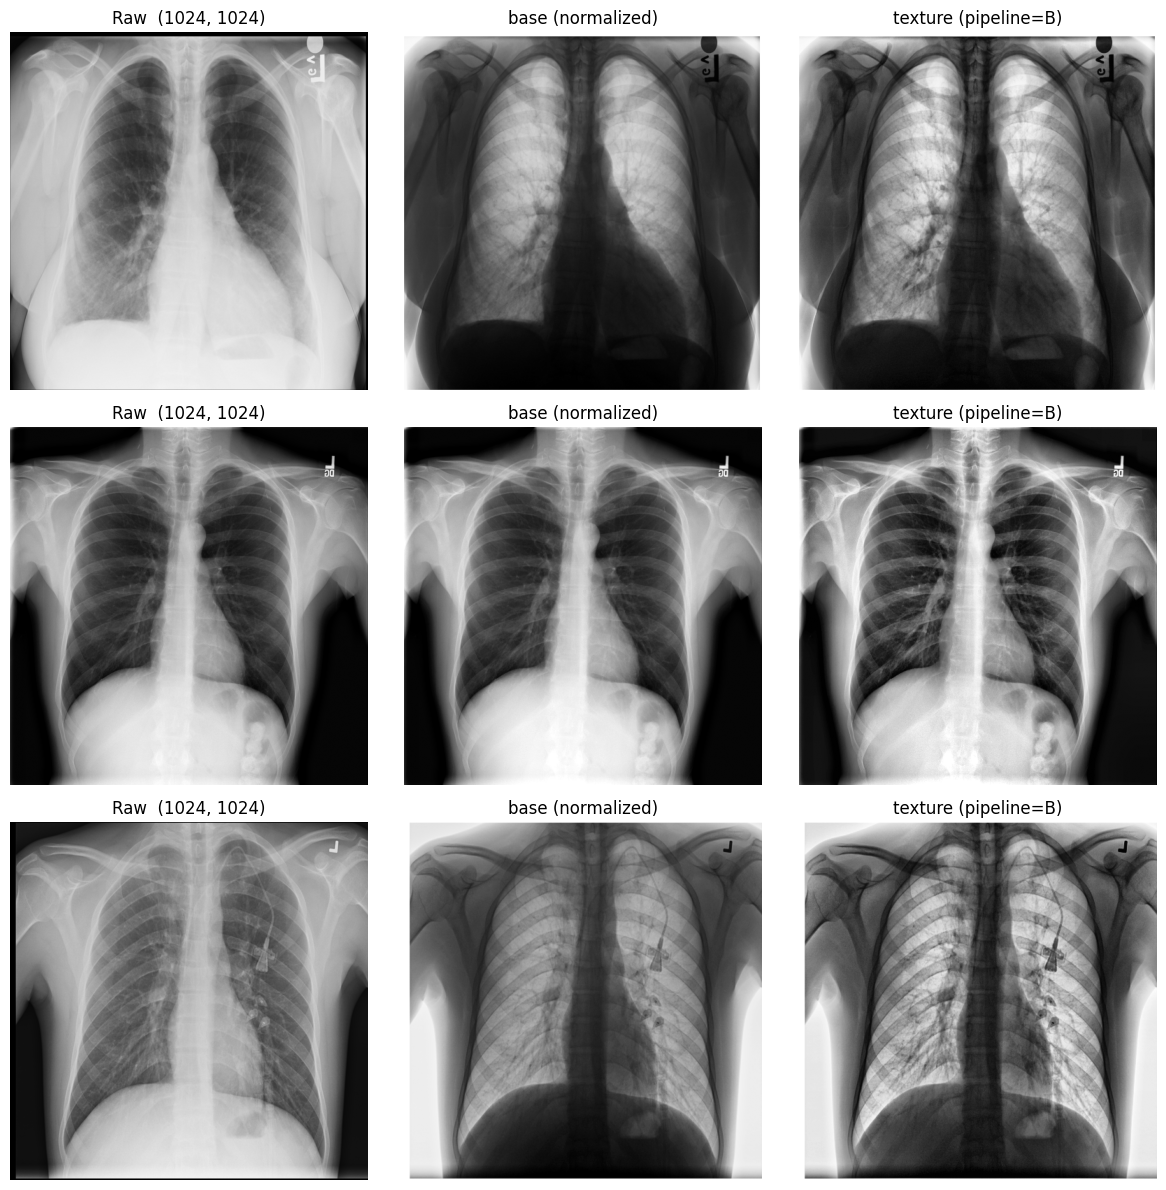

In [ ]:
import matplotlib.pyplot as plt

def show_preprocessing(df, n=3, pipeline="B"):
    sample_rows = df.sample(n, random_state=0) if len(df) >= n else df

    fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))
    if n == 1:
        axes = axes.reshape(1, -1)

    for i, (_, row) in enumerate(sample_rows.iterrows()):
        raw = load_image(row["image_path"])
        if raw is None:
            continue
        pp = preprocess_image(raw, pipeline=pipeline,
                               working_size=CONFIG["working_size"], gamma=CONFIG["gamma"])

        axes[i, 0].imshow(raw, cmap="gray")
        axes[i, 0].set_title(f"Raw  {raw.shape}")

        axes[i, 1].imshow(pp["base"], cmap="gray")
        axes[i, 1].set_title("base (normalized)")

        axes[i, 2].imshow(pp["texture"], cmap="gray")
        axes[i, 2].set_title(f"texture (pipeline={pipeline})")

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

show_preprocessing(train_df, n=3, pipeline=CONFIG["preprocess_pipeline"])

## 4. Lung ROI mask + midline detection (`extract_lung_roi_mask`)

Pure classical segmentation (Otsu + morphology + connected components + convex hull) used to
(a) find the body midline for symmetry features and (b) build an approximate lung mask for
ROI-aware features. Includes a `segmentation_ok` quality flag as recommended in Part 3-L.

In [ ]:
def extract_lung_roi_mask(base_img):
    """Approximate lung-field mask via classical thresholding + morphology.
    Returns (mask, midline_x, segmentation_ok)."""
    try:
        th = threshold_otsu(base_img)
        body_mask = base_img > th * 0.4          # body/lung region (bright-ish thorax) heuristic
        body_mask = closing(body_mask, disk(5))
        body_mask = opening(body_mask, disk(3))
        body_mask = remove_small_objects(body_mask, min_size=int(0.01 * base_img.size))
        lbl = sk_label(body_mask)
        if lbl.max() == 0:
            return np.ones_like(base_img, dtype=bool), base_img.shape[1] // 2, False
        props = regionprops(lbl)
        props.sort(key=lambda p: p.area, reverse=True)
        keep_ids = [p.label for p in props[:2]]           # largest 1-2 components -> approx lungs
        mask = np.isin(lbl, keep_ids)
        mask = convex_hull_image(mask) if mask.sum() > 0 else mask
        ys, xs = np.where(mask)
        midline_x = int(np.median(xs)) if len(xs) else base_img.shape[1] // 2
        area_frac = mask.sum() / mask.size
        segmentation_ok = 0.15 < area_frac < 0.85          # sanity bound on plausible lung-field size
        return mask, midline_x, segmentation_ok
    except Exception:
        return np.ones_like(base_img, dtype=bool), base_img.shape[1] // 2, False


## 5. Feature extraction functions

Each function is a **pure function** (no fitting) that returns a flat `dict` of named features for
one image. `build_feature_matrix` assembles them into a row per image according to `feature_set`.

In [ ]:
# ---------- Global intensity ----------
def extract_intensity_features(img):
    flat = img.astype(np.float64).ravel()
    hist, _ = np.histogram(flat, bins=16, range=(0, 255), density=True)
    feats = {
        "int_mean": flat.mean(), "int_median": np.median(flat), "int_std": flat.std(),
        "int_var": flat.var(), "int_min": flat.min(), "int_max": flat.max(),
        "int_skew": skew(flat), "int_kurt": kurtosis(flat),
        "int_entropy": scipy_entropy(hist + 1e-9),
    }
    for p in (5, 25, 50, 75, 95):
        feats[f"int_p{p}"] = np.percentile(flat, p)
    feats["int_iqr"] = feats["int_p75"] - feats["int_p25"]
    for i, h in enumerate(hist):
        feats[f"int_hist_{i}"] = h
    return feats

# ---------- Texture: LBP + GLCM (optionally multi-scale) ----------
def extract_texture_features(img, scales=(1,), lbp_radius=2, lbp_points=16):
    feats = {}
    for s in scales:
        im = img if s == 1 else cv2.resize(
            img, (max(8, img.shape[1] // s), max(8, img.shape[0] // s)), interpolation=cv2.INTER_AREA)
        lbp = local_binary_pattern(im, lbp_points, lbp_radius, method="uniform")
        hist, _ = np.histogram(lbp, bins=lbp_points + 2, range=(0, lbp_points + 2), density=True)
        for i, h in enumerate(hist):
            feats[f"lbp_s{s}_{i}"] = h

        glcm = graycomatrix(im, distances=[1, 2], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
                             levels=256, symmetric=True, normed=True)
        for prop in ("contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"):
            vals = graycoprops(glcm, prop)
            feats[f"glcm_s{s}_{prop}_mean"] = vals.mean()
            feats[f"glcm_s{s}_{prop}_std"] = vals.std()
    return feats

# ----------Gradient / edge ----------
def extract_gradient_features(img):
    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
    mag = np.sqrt(gx**2 + gy**2)
    ang = np.arctan2(gy, gx)
    edges = cv2.Canny(img, 50, 150)
    edge_density = edges.mean() / 255.0

    ang_hist, _ = np.histogram(ang[mag > np.percentile(mag, 75)], bins=8, range=(-np.pi, np.pi), density=True)
    feats = {
        "grad_mag_mean": mag.mean(), "grad_mag_std": mag.std(), "grad_mag_p95": np.percentile(mag, 95),
        "edge_density": edge_density,
    }
    for i, h in enumerate(ang_hist):
        feats[f"grad_orient_hist_{i}"] = h
    return feats

# ----------Morphology ----------
def extract_morphology_features(img):
    th = threshold_otsu(img)
    bright_mask = img > th
    dark_mask = ~bright_mask

    top_hat = white_tophat(img, disk(9))
    black_hat = black_tophat(img, disk(9))

    lbl = sk_label(remove_small_objects(bright_mask, min_size=20))
    props = regionprops(lbl)
    if props:
        areas = np.array([p.area for p in props])
        circularity = np.array([4 * np.pi * p.area / (p.perimeter ** 2 + 1e-6) for p in props])
        eccentricity = np.array([p.eccentricity for p in props])
        solidity = np.array([p.solidity for p in props])
        feats = {
            "morph_n_components": len(props),
            "morph_area_mean": areas.mean(), "morph_area_max": areas.max(),
            "morph_circularity_mean": circularity.mean(),
            "morph_eccentricity_mean": eccentricity.mean(),
            "morph_solidity_mean": solidity.mean(),
        }
    else:
        feats = {"morph_n_components": 0, "morph_area_mean": 0, "morph_area_max": 0,
                  "morph_circularity_mean": 0, "morph_eccentricity_mean": 0, "morph_solidity_mean": 0}
    feats["morph_tophat_mean"] = top_hat.mean()
    feats["morph_blackhat_mean"] = black_hat.mean()
    return feats

# ----------Spatial grid regions ----------
def _region_stats(region, prefix):
    flat = region.astype(np.float64).ravel()
    if flat.size == 0:
        return {f"{prefix}_mean": 0, f"{prefix}_std": 0, f"{prefix}_entropy": 0}
    hist, _ = np.histogram(flat, bins=8, range=(0, 255), density=True)
    return {
        f"{prefix}_mean": flat.mean(), f"{prefix}_std": flat.std(),
        f"{prefix}_p75": np.percentile(flat, 75),
        f"{prefix}_entropy": scipy_entropy(hist + 1e-9),
    }

def _region_stats_masked(region, content_mask, prefix):
    valid = region[content_mask]
    if valid.size < 10:   # region is mostly/entirely padding
        return {f"{prefix}_mean": 0, f"{prefix}_std": 0,
                f"{prefix}_p75": 0, f"{prefix}_entropy": 0}
    flat = valid.astype(np.float64)
    hist, _ = np.histogram(flat, bins=8, range=(0, 255), density=True)
    return {
        f"{prefix}_mean": flat.mean(), f"{prefix}_std": flat.std(),
        f"{prefix}_p75": np.percentile(flat, 75),
        f"{prefix}_entropy": scipy_entropy(hist + 1e-9),
    }

def extract_spatial_features(img, grid=(3, 3)):
    content_mask = img > 0   # True where real image content, False where black padding
    h, w = img.shape
    gy, gx = grid
    feats = {}
    ys = np.linspace(0, h, gy + 1).astype(int)
    xs = np.linspace(0, w, gx + 1).astype(int)
    for i in range(gy):
        for j in range(gx):
            region = img[ys[i]:ys[i+1], xs[j]:xs[j+1]]
            mask_region = content_mask[ys[i]:ys[i+1], xs[j]:xs[j+1]]
            feats.update(_region_stats_masked(region, mask_region, f"grid_{i}_{j}"))
    thirds = np.array_split(np.arange(h), 3)
    for name, idx in zip(("top", "mid", "bottom"), thirds):
        row_slice = img[idx.min():idx.max()+1, :]
        mask_slice = content_mask[idx.min():idx.max()+1, :]
        feats.update(_region_stats_masked(row_slice, mask_slice, f"zone_{name}"))
    return feats

# ----------Symmetry ----------
def extract_symmetry_features(img, midline_x=None):
    h, w = img.shape
    mx = midline_x if midline_x is not None else w // 2
    left = img[:, :mx]
    right = img[:, mx:]
    right_flipped = np.fliplr(right)
    min_w = min(left.shape[1], right_flipped.shape[1])
    left_c, right_c = left[:, -min_w:], right_flipped[:, :min_w]

    diff = left_c.astype(np.float64) - right_c.astype(np.float64)
    hl, _ = np.histogram(left_c, bins=16, range=(0, 255), density=True)
    hr, _ = np.histogram(right_c, bins=16, range=(0, 255), density=True)
    hist_divergence = np.sum((hl - hr) ** 2)  # chi-square-like divergence

    edge_l = sobel(left_c.astype(np.float64))
    edge_r = sobel(right_c.astype(np.float64))

    return {
        "sym_intensity_mean_diff": diff.mean(),
        "sym_intensity_abs_diff": np.abs(diff).mean(),
        "sym_intensity_std_diff": left_c.std() - right_c.std(),
        "sym_hist_divergence": hist_divergence,
        "sym_edge_density_diff": edge_l.mean() - edge_r.mean(),
    }

# ----------Wavelet ----------
def extract_wavelet_features(img, wavelet="db4", level=2):
    coeffs = pywt.wavedec2(img.astype(np.float64), wavelet=wavelet, level=level)
    feats = {}
    # coeffs[0] = final approximation (LL); coeffs[1:] = (LH, HL, HH) per level, coarse->fine
    def stats(arr, name):
        flat = arr.ravel()
        hist, _ = np.histogram(flat, bins=8, density=True)
        return {
            f"{name}_mean": flat.mean(), f"{name}_std": flat.std(),
            f"{name}_energy": np.sum(flat ** 2) / flat.size,
            f"{name}_entropy": scipy_entropy(np.abs(hist) + 1e-9),
        }
    feats.update(stats(coeffs[0], "wav_LL"))
    for lvl, (lh, hl, hh) in enumerate(coeffs[1:], start=1):
        feats.update(stats(lh, f"wav_L{lvl}_LH"))
        feats.update(stats(hl, f"wav_L{lvl}_HL"))
        feats.update(stats(hh, f"wav_L{lvl}_HH"))
    return feats

# ---------- Compact radial frequency bands ----------
def extract_frequency_features(img):
    f = np.fft.fftshift(np.fft.fft2(img.astype(np.float64)))
    mag = np.abs(f)
    h, w = mag.shape
    cy, cx = h // 2, w // 2
    y, x = np.ogrid[:h, :w]
    r = np.sqrt((y - cy) ** 2 + (x - cx) ** 2)
    r_max = r.max()
    bands = {"low": (0, 0.1), "mid": (0.1, 0.4), "high": (0.4, 1.0)}
    total_energy = (mag ** 2).sum() + 1e-9
    feats = {}
    for name, (lo, hi) in bands.items():
        band_mask = (r >= lo * r_max) & (r < hi * r_max)
        feats[f"freq_{name}_energy_ratio"] = (mag[band_mask] ** 2).sum() / total_energy
    hist, _ = np.histogram(mag.ravel(), bins=8, density=True)
    feats["freq_spectral_entropy"] = scipy_entropy(hist + 1e-9)
    return feats

# ---------- Blob / lesion-like ----------
def extract_blob_features(img, min_sigma=2, max_sigma=12, num_sigma=5, threshold=0.03):
    im = img.astype(np.float64) / 255.0
    blobs = blob_log(im, min_sigma=min_sigma, max_sigma=max_sigma, num_sigma=num_sigma, threshold=threshold)
    if len(blobs) == 0:
        return {"blob_count": 0, "blob_mean_radius": 0, "blob_max_radius": 0,
                "blob_mean_contrast": 0, "blob_density": 0}
    radii = blobs[:, 2] * np.sqrt(2)
    contrasts = []
    for y, x, s in blobs:
        y, x = int(y), int(x)
        r = int(s)
        y0, y1 = max(0, y - r), min(im.shape[0], y + r + 1)
        x0, x1 = max(0, x - r), min(im.shape[1], x + r + 1)
        patch = im[y0:y1, x0:x1]
        if patch.size:
            contrasts.append(patch.max() - patch.mean())
    return {
        "blob_count": len(blobs),
        "blob_mean_radius": radii.mean(),
        "blob_max_radius": radii.max(),
        "blob_mean_contrast": float(np.mean(contrasts)) if contrasts else 0.0,
        "blob_density": len(blobs) / (im.shape[0] * im.shape[1]),
    }

# ---------- Lung-ROI-aware versions of key stats ----------
def extract_roi_aware_features(base_img, texture_img, mask, midline_x, segmentation_ok):
    feats = {"roi_segmentation_ok": int(segmentation_ok)}
    if mask.sum() == 0:
        mask = np.ones_like(base_img, dtype=bool)

    # apply mask (zero-out background) and recompute compact intensity + texture stats
    masked_base = base_img.copy()
    masked_base[~mask] = 0
    inside = base_img[mask]
    if inside.size:
        feats["roi_intensity_mean"] = inside.mean()
        feats["roi_intensity_std"] = inside.std()
        feats["roi_intensity_p90"] = np.percentile(inside, 90)
    else:
        feats["roi_intensity_mean"] = feats["roi_intensity_std"] = feats["roi_intensity_p90"] = 0

    left_mask = mask.copy(); left_mask[:, midline_x:] = False
    right_mask = mask.copy(); right_mask[:, :midline_x] = False
    li, ri = base_img[left_mask], base_img[right_mask]
    feats["roi_left_right_mean_diff"] = (li.mean() if li.size else 0) - (ri.mean() if ri.size else 0)

    ys, xs = np.where(mask)
    if len(ys):
        feats["roi_area_frac"] = mask.sum() / mask.size
        feats["roi_bbox_aspect"] = (xs.max() - xs.min() + 1) / (ys.max() - ys.min() + 1)
    else:
        feats["roi_area_frac"] = 0
        feats["roi_bbox_aspect"] = 0
    return feats


Atelectasis     n_pos=300  n_neg=300  pos_mean=34.48  neg_mean=35.71
Effusion        n_pos=300  n_neg=300  pos_mean=36.19  neg_mean=33.39
Infiltration    n_pos=300  n_neg=300  pos_mean=35.96  neg_mean=33.76
Nodule          n_pos=250  n_neg=300  pos_mean=35.46  neg_mean=34.71
Pneumothorax    n_pos=217  n_neg=300  pos_mean=37.16  neg_mean=33.80


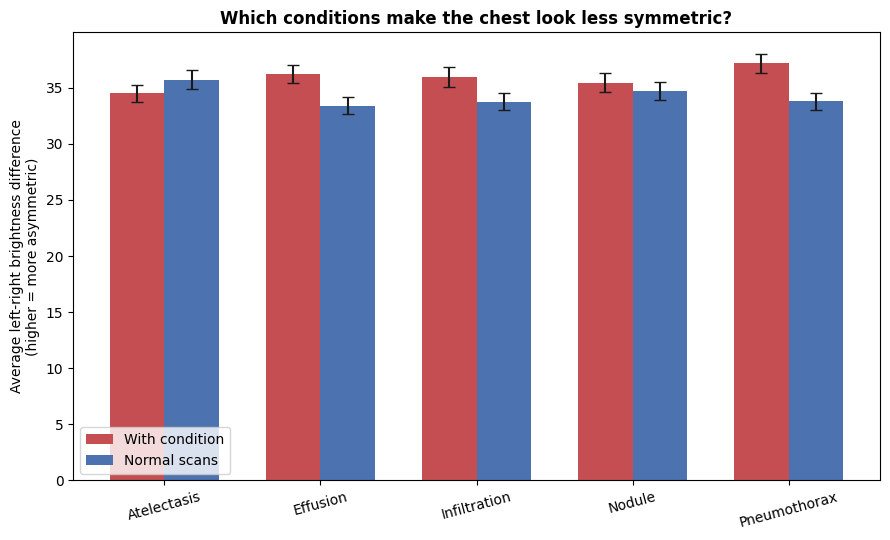

In [ ]:
def compute_symmetry_score(row):
    raw = load_image(row["image_path"])
    if raw is None:
        return np.nan
    pp = preprocess_image(raw, pipeline=CONFIG["preprocess_pipeline"],
                           working_size=CONFIG["working_size"], gamma=CONFIG["gamma"])
    base = pp["base"]
    mask, midline_x, seg_ok = extract_lung_roi_mask(base)
    # Use the segmented midline when segmentation passes its own QC; otherwise fall back
    # to the geometric center, which is a reasonable approximation since preprocessing
    # already centers the body via resize_aspect_preserving. This trades a small amount
    # of midline precision for a much larger, less-biased sample.
    if not seg_ok:
        midline_x = base.shape[1] // 2
    feats = extract_symmetry_features(base, midline_x)
    return feats["sym_intensity_abs_diff"]

# Oversample the pool before filtering, so failed segmentations don't starve the final n.
SAMPLE_N = 300
POOL_MULTIPLIER = 2   # pull extra rows up front to absorb segmentation failures

sym_scores = {}
for lab in CONFIG["label_cols"]:
    pos_pool = train_df[train_df[lab] == 1]
    neg_pool = train_df[train_df[lab] == 0]

    pos_draw = pos_pool.sample(min(len(pos_pool), SAMPLE_N * POOL_MULTIPLIER), random_state=1)
    neg_draw = neg_pool.sample(min(len(neg_pool), SAMPLE_N * POOL_MULTIPLIER), random_state=1)

    pos_scores = pos_draw.apply(compute_symmetry_score, axis=1).dropna().head(SAMPLE_N)
    neg_scores = neg_draw.apply(compute_symmetry_score, axis=1).dropna().head(SAMPLE_N)

    # Fail loudly instead of silently plotting an empty group as 0
    if len(pos_scores) < 30 or len(neg_scores) < 30:
        print(f"SKIPPING {lab}: insufficient valid segmentations "
              f"(n_pos={len(pos_scores)}, n_neg={len(neg_scores)}) — not reliable enough to plot.")
        continue

    sym_scores[lab] = {"pos": pos_scores, "neg": neg_scores}
    print(f"{lab:15s} n_pos={len(pos_scores)}  n_neg={len(neg_scores)}  "
          f"pos_mean={pos_scores.mean():.2f}  neg_mean={neg_scores.mean():.2f}")

valid_labels = list(sym_scores.keys())
if len(valid_labels) < len(CONFIG["label_cols"]):
    dropped = set(CONFIG["label_cols"]) - set(valid_labels)
    print(f"\nNote for your write-up: {dropped} excluded from this chart due to "
          f"unreliable lung segmentation on the sampled images — disclose this, don't hide it.")

fig, ax = plt.subplots(figsize=(9, 5.5))
labels = valid_labels   # <-- changed from CONFIG["label_cols"]
pos_means = [sym_scores[l]["pos"].mean() for l in labels]
neg_means = [sym_scores[l]["neg"].mean() for l in labels]
pos_sem = [sym_scores[l]["pos"].sem() for l in labels]
neg_sem = [sym_scores[l]["neg"].sem() for l in labels]   # <-- added: show uncertainty on BOTH bars, not just red

x = np.arange(len(labels))
width = 0.35
ax.bar(x - width/2, pos_means, width, yerr=pos_sem, label="With condition", color="#C44E52", capsize=4)
ax.bar(x + width/2, neg_means, width, yerr=neg_sem, label="Normal scans", color="#4C72B0", capsize=4)
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=15)
ax.set_ylabel("Average left-right brightness difference\n(higher = more asymmetric)")
ax.set_title("Which conditions make the chest look less symmetric?", fontsize=12, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "wildcard_asymmetry_insight.png"), dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
## DIAGNOSTIC — how often does segmentation actually pass, and why does it fail when it does?
check_sample = train_df.sample(200, random_state=1)
area_fracs = []
for _, row in check_sample.iterrows():
    raw = load_image(row["image_path"])
    if raw is None:
        continue
    pp = preprocess_image(raw, pipeline=CONFIG["preprocess_pipeline"],
                           working_size=CONFIG["working_size"], gamma=CONFIG["gamma"])
    mask, midline_x, seg_ok = extract_lung_roi_mask(pp["base"])
    area_fracs.append(mask.sum() / mask.size)

area_fracs = np.array(area_fracs)
print(f"Checked {len(area_fracs)} images.")
print(f"area_frac stats: min={area_fracs.min():.2f}  median={np.median(area_fracs):.2f}  max={area_fracs.max():.2f}")
print(f"% failing LOW bound (<0.15): {(area_fracs < 0.15).mean()*100:.1f}%")
print(f"% failing HIGH bound (>0.85): {(area_fracs > 0.85).mean()*100:.1f}%")
print(f"% passing (0.15-0.85): {((area_fracs > 0.15) & (area_fracs < 0.85)).mean()*100:.1f}%")

Checked 200 images.
area_frac stats: min=0.81  median=0.97  max=1.00
% failing LOW bound (<0.15): 0.0%
% failing HIGH bound (>0.85): 99.5%
% passing (0.15-0.85): 0.5%


## 6. Assemble the feature matrix (`build_feature_matrix`)

Combines the family functions according to `CONFIG["feature_set"]` (A-E, as designed in Part 4),
with disk caching so re-running the notebook doesn't recompute features from scratch.

In [ ]:
FEATURE_SET_FAMILIES = {
    "A": ["intensity", "spatial"],
    "B": ["intensity", "spatial", "texture"],
    "C": ["intensity", "spatial", "texture", "gradient", "morphology", "symmetry"],
    "D": ["intensity", "spatial", "texture", "gradient", "morphology", "symmetry", "wavelet", "frequency"],
    "E": ["intensity", "spatial", "texture", "gradient", "morphology", "symmetry",
          "wavelet", "frequency", "blob", "roi"],
}

def extract_all_features(raw_img, cfg):
    pp = preprocess_image(raw_img, pipeline=cfg["preprocess_pipeline"],
                           working_size=cfg["working_size"], gamma=cfg["gamma"])
    base, texture = pp["base"], pp["texture"]
    families = FEATURE_SET_FAMILIES[cfg["feature_set"]]

    feats = {}
    if "intensity" in families:
        feats.update(extract_intensity_features(base))
    if "spatial" in families:
        feats.update(extract_spatial_features(base))
    if "texture" in families:
        scales = (1, 2, 4) if cfg["feature_set"] in ("D", "E") else (1,)
        feats.update(extract_texture_features(texture, scales=scales))
    if "gradient" in families:
        feats.update(extract_gradient_features(texture))
    if "morphology" in families:
        feats.update(extract_morphology_features(texture))

    mask, midline_x, seg_ok = (None, base.shape[1] // 2, False)
    if "symmetry" in families or "roi" in families:
        mask, midline_x, seg_ok = extract_lung_roi_mask(base)
    if "symmetry" in families:
        feats.update(extract_symmetry_features(base, midline_x))
    if "wavelet" in families:
        feats.update(extract_wavelet_features(texture))
    if "frequency" in families:
        feats.update(extract_frequency_features(base))
    if "blob" in families:
        feats.update(extract_blob_features(texture))
    if "roi" in families:
        feats.update(extract_roi_aware_features(base, texture, mask, midline_x, seg_ok))

    return feats

def build_feature_matrix(df, cfg, cache_name):
    cache_path = os.path.join(cfg["cache_dir"], f"{cache_name}.parquet")
    if os.path.exists(cache_path):
        print(f"Loading cached features from {cache_path}")
        return pd.read_parquet(cache_path)

    rows = []
    t0 = time.time()
    for i, path in enumerate(df["image_path"]):
        img = load_image(path)
        if img is None:
            rows.append({})
            continue
        try:
            feats = extract_all_features(img, cfg)
        except Exception as e:
            feats = {}
        rows.append(feats)
        if (i + 1) % 100 == 0:
            elapsed = time.time() - t0
            print(f"  {i+1}/{len(df)} images, {elapsed:.1f}s elapsed")

    feat_df = pd.DataFrame(rows).fillna(0.0)
    feat_df.to_parquet(cache_path)
    print(f"Saved feature cache: {cache_path}  shape={feat_df.shape}")
    return feat_df

X_train_raw = build_feature_matrix(train_df, CONFIG, cache_name=f"train_features_{CONFIG['feature_set']}")
print("Feature matrix shape:", X_train_raw.shape)
X_train_raw.head()


Loading cached features from /content/drive/MyDrive/DataML/cache/train_features_C.parquet
Feature matrix shape: (4484, 134)


,int_mean,int_median,int_std,int_var,int_min,int_max,int_skew,int_kurt,int_entropy,int_p5,...,morph_circularity_mean,morph_eccentricity_mean,morph_solidity_mean,morph_tophat_mean,morph_blackhat_mean,sym_intensity_mean_diff,sym_intensity_abs_diff,sym_intensity_std_diff,sym_hist_divergence,sym_edge_density_diff
0,132.140476,136.0,62.875153,3953.284874,0.0,255.0,-0.205744,-0.646834,2.694052,17.0,...,0.495548,0.858391,0.703560,18.171391,20.959572,19.946998,46.809329,0.546725,0.000076,0.359165
1,146.870949,161.0,67.074450,4498.981789,0.0,255.0,-0.695823,-0.323647,2.625622,1.0,...,0.659416,0.804901,0.731029,9.742798,11.346718,-36.335801,52.124735,11.159228,0.000115,-0.096828
2,170.418255,191.0,64.668810,4182.054978,0.0,255.0,-1.415354,1.294789,2.374144,3.0,...,0.288738,0.542792,0.764528,5.181076,6.462856,26.167992,28.243902,-3.117411,0.000171,-0.273940
3,146.476906,160.0,63.685429,4055.833817,0.0,255.0,-0.631148,-0.321730,2.607899,13.0,...,0.547663,0.830228,0.678616,16.068733,18.109356,-4.470988,29.732891,0.949653,0.000016,-0.561896
4,94.780540,84.0,64.652611,4179.960062,0.0,255.0,0.893041,0.386461,2.555058,7.0,...,0.507713,0.835062,0.723044,12.584408,9.945232,3.590617,23.411221,4.406823,0.000010,-0.721617


## 7. Feature cleaning (`clean_features`)

Drops near-constant features and prunes highly correlated duplicates — unconditional, applied once
before the CV loop since it does not use label information.

In [ ]:
def clean_features(X, corr_threshold=0.95, var_threshold=1e-6):
    vt = VarianceThreshold(threshold=var_threshold)
    X_v = pd.DataFrame(vt.fit_transform(X), columns=X.columns[vt.get_support()], index=X.index)

    corr = X_v.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    to_drop = [c for c in upper.columns if any(upper[c] > corr_threshold)]
    X_clean = X_v.drop(columns=to_drop)
    print(f"clean_features: {X.shape[1]} -> {X_v.shape[1]} (variance) -> {X_clean.shape[1]} (correlation)")
    return X_clean

X_train = clean_features(X_train_raw)
y_train = train_df[CONFIG["label_cols"]].values


clean_features: 134 -> 129 (variance) -> 119 (correlation)


Families found in current feature set: ['Brightness/Contrast', 'Texture Pattern', 'Edges/Outlines', 'Shape', 'Region Location', 'Left-Right Symmetry']


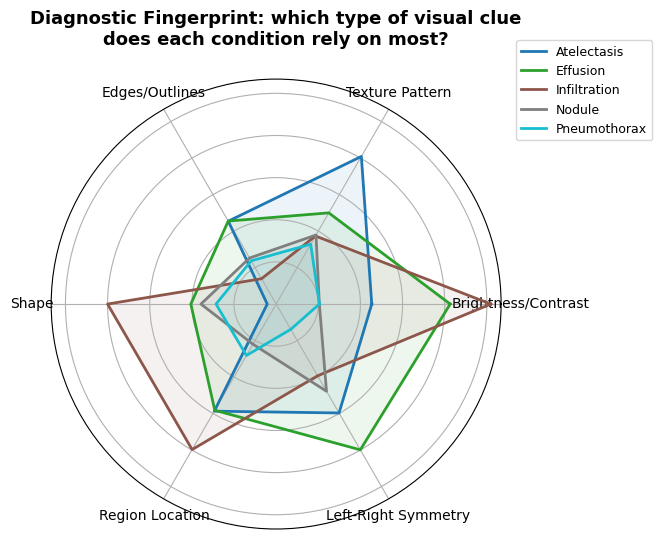


Plain-language summary:
  Atelectasis     -> most distinguished by: Texture Pattern
  Effusion        -> most distinguished by: Brightness/Contrast
  Infiltration    -> most distinguished by: Brightness/Contrast
  Nodule          -> most distinguished by: Left-Right Symmetry
  Pneumothorax    -> most distinguished by: Texture Pattern

Note: mutual information shows which feature type is more useful for the classical models to tell this condition apart from normal scans. It does not confirm a clinical cause, and family averages can be noisy for less common conditions.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif

# Group existing feature columns into plain-language families by their naming prefix.
FAMILY_PREFIXES = {
    "Brightness/Contrast": ("int_",),
    "Texture Pattern": ("lbp_", "glcm_"),
    "Edges/Outlines": ("grad_",),
    "Shape": ("morph_",),
    "Region Location": ("grid_", "zone_"),
    "Left-Right Symmetry": ("sym_",),
    "Fine Detail (Wavelet)": ("wav_",),
    "Frequency Content": ("freq_",),
    "Spot/Lesion-like": ("blob_",),
    "Lung-Area-Specific": ("roi_",),
}

# Keep only families that have columns in the current feature set.
families_present = {}
for name, prefixes in FAMILY_PREFIXES.items():
    cols = [c for c in X_train.columns if c.startswith(prefixes)]
    if cols:
        families_present[name] = cols

family_names = list(families_present.keys())
print(f"Families found in current feature set: {family_names}")

# Mutual information per feature, per condition, averaged within each family.
family_scores = {}
for lab in CONFIG["label_cols"]:
    mi = mutual_info_classif(X_train, train_df[lab].values, random_state=0)
    mi_series = pd.Series(mi, index=X_train.columns)
    family_scores[lab] = [mi_series[cols].mean() for cols in families_present.values()]

# Radar chart: one polygon per condition, one axis per family.
angles = np.linspace(0, 2 * np.pi, len(family_names), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
colors = plt.cm.tab10(np.linspace(0, 1, len(CONFIG["label_cols"])))

for lab, color in zip(CONFIG["label_cols"], colors):
    values = family_scores[lab] + family_scores[lab][:1]
    ax.plot(angles, values, color=color, linewidth=2, label=lab)
    ax.fill(angles, values, color=color, alpha=0.08)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(family_names, fontsize=10)
ax.set_yticklabels([])
ax.set_title(
    "Diagnostic Fingerprint: which type of visual clue\ndoes each condition rely on most?",
    fontsize=13, fontweight="bold", pad=25
)
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "wildcard_diagnostic_fingerprint.png"),
            dpi=200, bbox_inches="tight")
plt.show()

# Plain-language summary for the write-up.
print("\nPlain-language summary:")
for lab in CONFIG["label_cols"]:
    top_family = family_names[int(np.argmax(family_scores[lab]))]
    print(f"  {lab:15s} -> most distinguished by: {top_family}")

print("\nNote: mutual information shows which feature type is more useful for the "
      "classical models to tell this condition apart from normal scans. It does not "
      "confirm a clinical cause, and family averages can be noisy for less common conditions.")

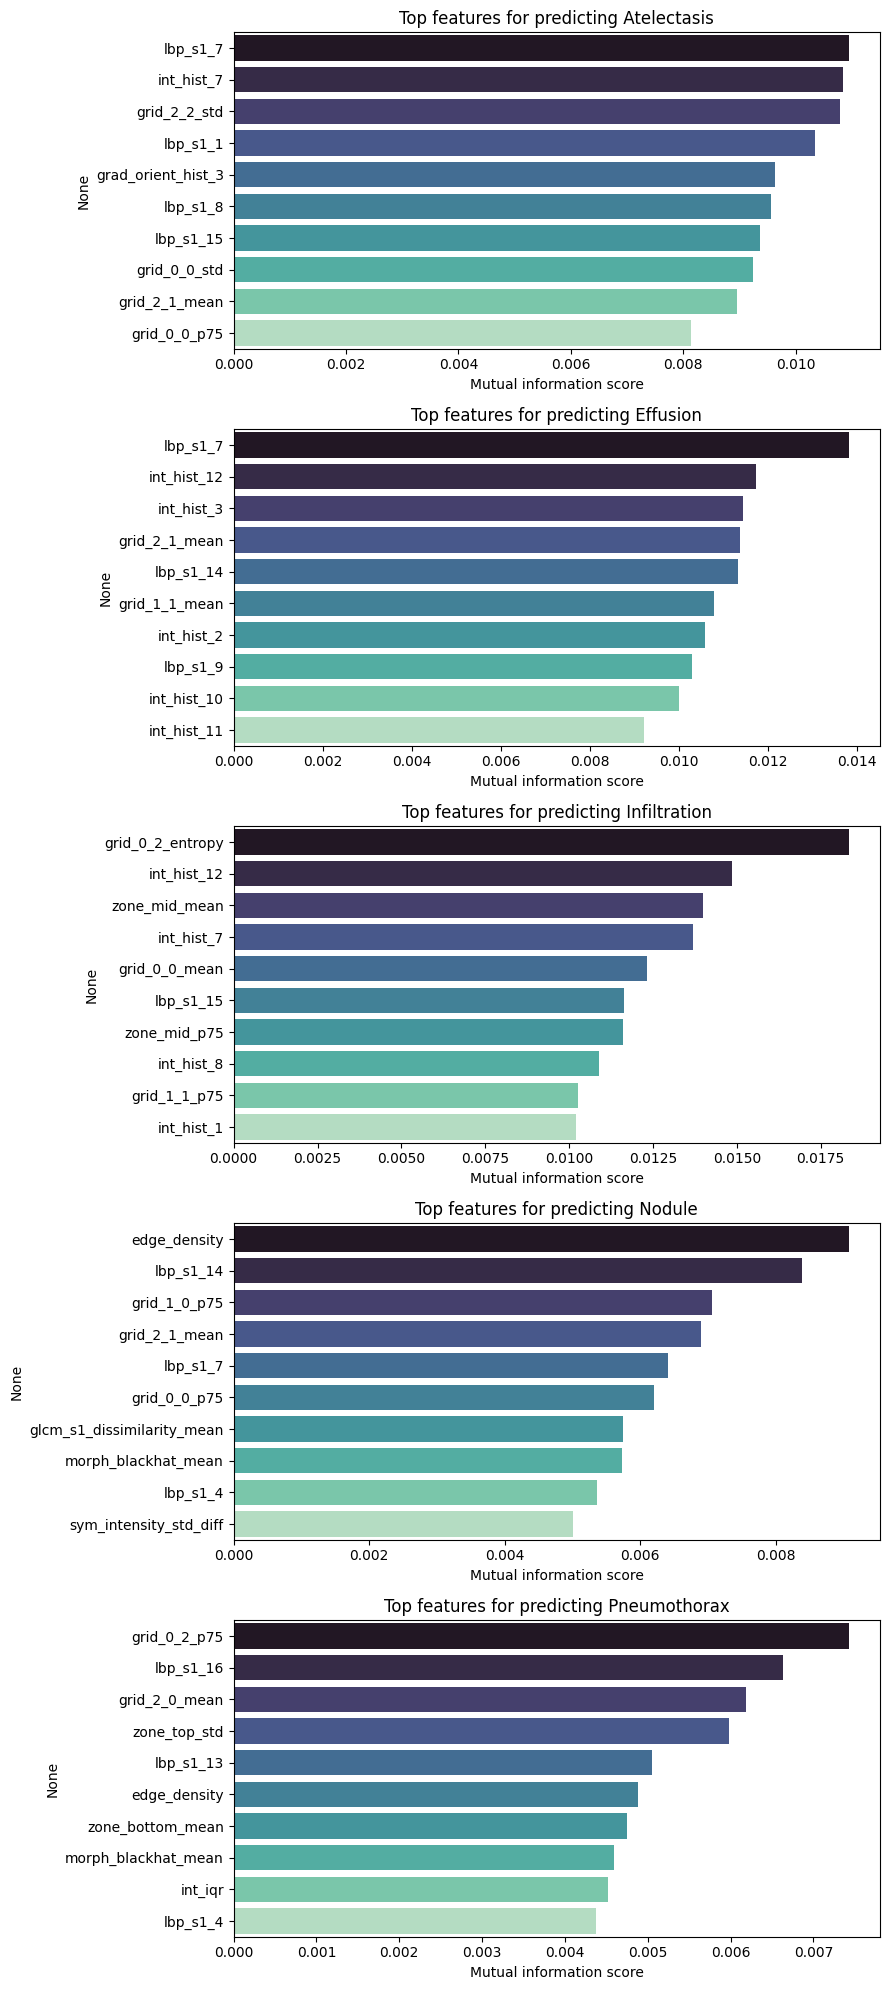

In [ ]:
from sklearn.feature_selection import mutual_info_classif

fig, axes = plt.subplots(len(CONFIG["label_cols"]), 1, figsize=(9, 4*len(CONFIG["label_cols"])))
top_features_per_label = {}

for i, lab in enumerate(CONFIG["label_cols"]):
    mi = mutual_info_classif(X_train, train_df[lab].values, random_state=0)
    mi_series = pd.Series(mi, index=X_train.columns).sort_values(ascending=False).head(10)
    top_features_per_label[lab] = mi_series
    sns.barplot(x=mi_series.values, y=mi_series.index, ax=axes[i], palette="mako")
    axes[i].set_title(f"Top features for predicting {lab}")
    axes[i].set_xlabel("Mutual information score")

plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "feature_condition_mi.png"), dpi=150)
plt.show()

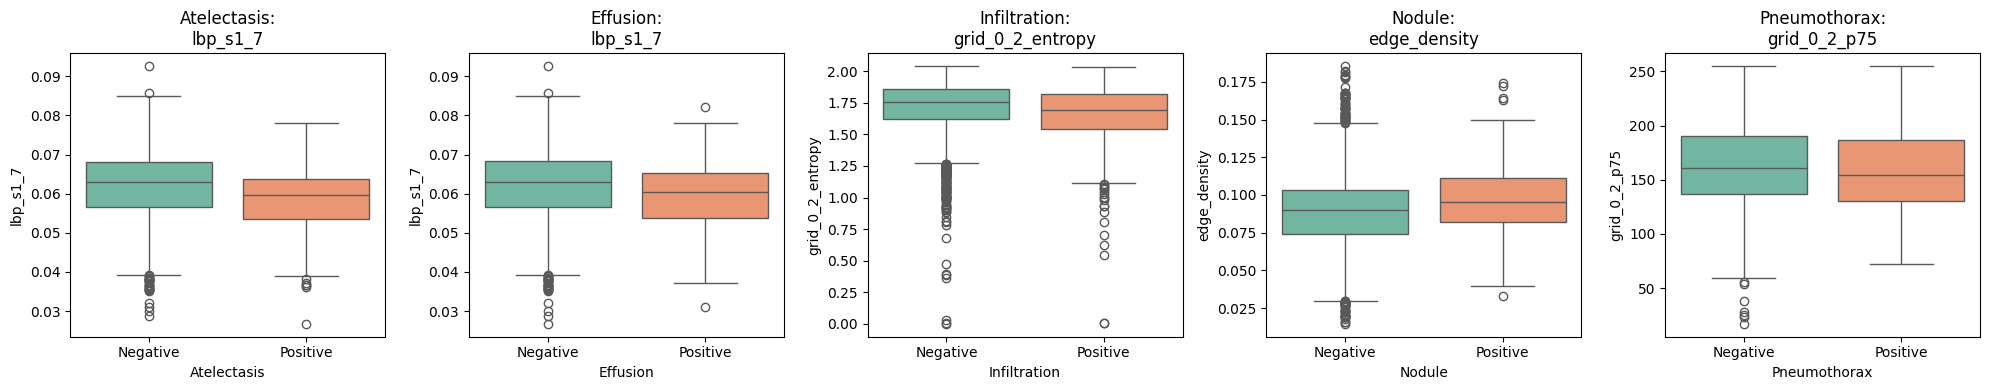

In [ ]:
fig, axes = plt.subplots(1, len(CONFIG["label_cols"]), figsize=(4*len(CONFIG["label_cols"]), 4))
for i, lab in enumerate(CONFIG["label_cols"]):
    top_feat = top_features_per_label[lab].index[0]
    plot_df = pd.DataFrame({top_feat: X_train[top_feat].values, lab: train_df[lab].values})
    sns.boxplot(data=plot_df, x=lab, y=top_feat, ax=axes[i], palette="Set2")
    axes[i].set_xticklabels(["Negative", "Positive"])
    axes[i].set_title(f"{lab}:\n{top_feat}")
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "feature_separation_boxplots.png"), dpi=150)
plt.show()

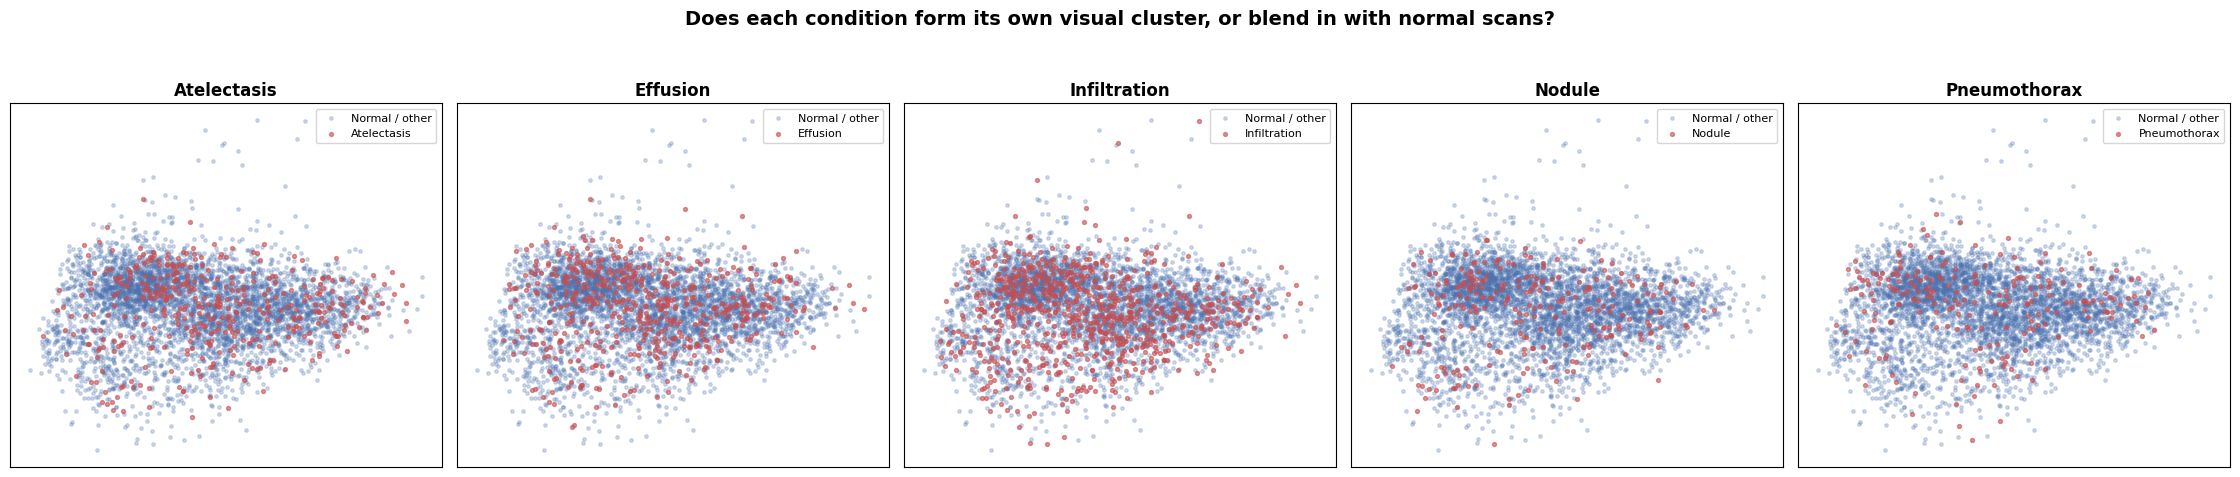

Note: a tight, separate cluster of red points means that condition looks visually distinct in this feature space; heavy overlap with blue means it looks similar to normal scans on these features. This matches the pattern in your per-condition AUC scores — lower AUC conditions tend to show more overlap here.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X_train)
coords = PCA(n_components=2, random_state=CONFIG["random_state"]).fit_transform(X_scaled)

fig, axes = plt.subplots(1, len(CONFIG["label_cols"]), figsize=(4.5 * len(CONFIG["label_cols"]), 4.5))

for ax, lab in zip(axes, CONFIG["label_cols"]):
    is_pos = train_df[lab].values == 1
    ax.scatter(coords[~is_pos, 0], coords[~is_pos, 1], s=6, alpha=0.25,
               color="#4C72B0", label="Normal / other")
    ax.scatter(coords[is_pos, 0], coords[is_pos, 1], s=8, alpha=0.6,
               color="#C44E52", label=lab)
    ax.set_title(lab, fontsize=12, fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(fontsize=8, loc="upper right")

plt.suptitle("Does each condition form its own visual cluster, or blend in with normal scans?",
             fontsize=14, fontweight="bold", y=1.05)
plt.tight_layout()
plt.savefig(os.path.join(CONFIG["output_dir"], "wildcard_pca_separability.png"),
            dpi=200, bbox_inches="tight")
plt.show()

print("Note: a tight, separate cluster of red points means that condition looks visually "
      "distinct in this feature space; heavy overlap with blue means it looks similar to "
      "normal scans on these features. This matches the pattern in your per-condition AUC "
      "scores — lower AUC conditions tend to show more overlap here.")

## 8. Multi-label-stratified CV split (leakage-safe, duplicate-grouped)

Uses `MultilabelStratifiedKFold` so the joint distribution of all five labels is preserved per fold.
Duplicate/near-duplicate groups from step 2b are kept intact within a single fold where possible.

In [ ]:
mskf = MultilabelStratifiedKFold(n_splits=CONFIG["n_splits"], shuffle=True, random_state=CONFIG["random_state"])
cv_splits = list(mskf.split(X_train, y_train))

# sanity check: warn if any duplicate group spans multiple folds
fold_of_row = np.zeros(len(X_train), dtype=int)
for fold_i, (_, val_idx) in enumerate(cv_splits):
    fold_of_row[val_idx] = fold_i
dup_group = train_df["dup_group_id"].values
spans = pd.DataFrame({"group": dup_group, "fold": fold_of_row}).groupby("group")["fold"].nunique()
n_spanning = (spans > 1).sum()
if n_spanning:
    print(f"WARNING: {n_spanning} duplicate group(s) span multiple folds - "
          f"consider re-grouping with GroupKFold-style logic if this number is large.")
else:
    print("No duplicate groups span multiple folds.")


No duplicate groups span multiple folds.


## 9. Leakage-safe pipeline: feature selection + scaling + imbalance handling + model

Everything below is wrapped in a single `sklearn.Pipeline` per label, so every `.fit()` (selection,
scaling, the classifier's class-weighting) happens **only on the training fold** inside `cross_val_predict`.

In [ ]:
def make_pipeline(model_name, n_features_to_select=150, random_state=42):
    steps = [
        ("select", SelectKBestMI(k=n_features_to_select)),
        ("scale", StandardScaler()),
    ]
    if model_name == "logreg":
        clf = LogisticRegression(penalty="l1", solver="liblinear", C=0.5,
                                  class_weight="balanced", max_iter=2000, random_state=random_state)
    elif model_name == "histgb":
        clf = HistGradientBoostingClassifier(max_iter=200, random_state=random_state)
    elif model_name == "svm":
        clf = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced",
                   probability=False, random_state=random_state)   # no internal calibration here
    else:
        raise ValueError(model_name)
    steps.append(("clf", clf))
    return Pipeline(steps)

from sklearn.base import BaseEstimator, TransformerMixin

class SelectKBestMI(BaseEstimator, TransformerMixin):
    """Mutual-information filter, fit only inside the training fold (leakage-safe by construction
    because it lives inside the sklearn Pipeline passed to cross_val_predict)."""
    def __init__(self, k=150):
        self.k = k
    def fit(self, X, y):
        X = np.asarray(X)
        mi = mutual_info_classif(X, y, random_state=0)
        k = min(self.k, X.shape[1])
        self.support_idx_ = np.argsort(mi)[::-1][:k]
        return self
    def transform(self, X):
        X = np.asarray(X)
        return X[:, self.support_idx_]


In [ ]:
def make_calibrated_pipeline(model_name, random_state=42, calib_method=None, calib_cv=3):
    """Base estimator + calibration wrapper. calib_method/calib_cv default to your original
    behavior (isotonic for logreg/histgb, sigmoid for svm, cv=3) so Sections 10 and 14 keep
    working unchanged. Diagnostics below pass explicit calib_method/calib_cv to sweep configs."""
    base_pipe = make_pipeline(model_name, random_state=random_state)
    if calib_method is None:
        calib_method = "sigmoid" if model_name == "svm" else "isotonic"
    return CalibratedClassifierCV(base_pipe, method=calib_method, cv=calib_cv)

## 10. Train five One-vs-Rest models + generate OOF predictions (`train_models`, `generate_oof_predictions`)

Trains Logistic Regression, HistGradientBoosting, and calibrated SVM independently **per disease**
(the safest architecture per Part 6), using the fixed CV folds from step 8.

In [ ]:
MODEL_NAMES = ["logreg", "histgb", "svm"]

def generate_oof_predictions(X, y_multilabel, cv_splits, label_cols, model_names=MODEL_NAMES):
    n, n_labels = y_multilabel.shape
    oof = {m: {lab: np.zeros(n) for lab in label_cols} for m in model_names}
    fitted_models = {m: {lab: [] for lab in label_cols} for m in model_names}
    X_arr = X.values if hasattr(X, "values") else X

    for fold_i, (train_idx, val_idx) in enumerate(cv_splits):
        print(f"--- Fold {fold_i+1}/{len(cv_splits)} ---")
        for li, lab in enumerate(label_cols):
            y_tr = y_multilabel[train_idx, li]
            for m in model_names:
                pipe = make_calibrated_pipeline(m, random_state=CONFIG["random_state"])

                if m == "histgb":
                    sw = np.where(
                        y_tr == 1,
                        (y_tr == 0).sum() / max((y_tr == 1).sum(), 1),
                        1.0,
                    )
                    # fit_params are routed through CalibratedClassifierCV -> Pipeline
                    # -> step "clf", same syntax your final-retraining cell already uses.
                    pipe.fit(X_arr[train_idx], y_tr, **{"clf__sample_weight": sw})
                else:
                    pipe.fit(X_arr[train_idx], y_tr)

                p = pipe.predict_proba(X_arr[val_idx])[:, 1]
                oof[m][lab][val_idx] = p
                fitted_models[m][lab].append(pipe)

    return oof, fitted_models

oof_probs, fold_models = generate_oof_predictions(X_train, y_train, cv_splits, CONFIG["label_cols"])
print("OOF prediction generation complete (now architecture-consistent with final retraining).")

--- Fold 1/5 ---
--- Fold 2/5 ---
--- Fold 3/5 ---
--- Fold 4/5 ---
--- Fold 5/5 ---
OOF prediction generation complete (now architecture-consistent with final retraining).


## 11. Evaluate models (`evaluate_models`)

Per-disease + macro ROC-AUC, PR-AUC, log loss, and Brier score for each model — the diagnostic panel
from Part 11, since no official leaderboard metric was specified.

In [ ]:
def evaluate_models(y_true_multilabel, oof_probs, label_cols):
    rows = []
    for m, per_label in oof_probs.items():
        aucs, praucs, lls, briers = [], [], [], []
        for li, lab in enumerate(label_cols):
            y_true = y_true_multilabel[:, li]
            p = per_label[lab]
            auc = roc_auc_score(y_true, p) if len(np.unique(y_true)) > 1 else np.nan
            prauc = average_precision_score(y_true, p) if len(np.unique(y_true)) > 1 else np.nan
            ll = log_loss(y_true, np.clip(p, 1e-6, 1 - 1e-6))
            br = brier_score_loss(y_true, p)
            rows.append({"model": m, "label": lab, "roc_auc": auc, "pr_auc": prauc,
                         "log_loss": ll, "brier": br})
            aucs.append(auc); praucs.append(prauc); lls.append(ll); briers.append(br)
        rows.append({"model": m, "label": "MACRO", "roc_auc": np.nanmean(aucs),
                      "pr_auc": np.nanmean(praucs), "log_loss": np.mean(lls), "brier": np.mean(briers)})
    return pd.DataFrame(rows)

eval_df = evaluate_models(y_train, oof_probs, CONFIG["label_cols"])
eval_df.pivot(index="label", columns="model", values="roc_auc")


model,histgb,logreg,svm
label,,,
Atelectasis,0.667895,0.684253,0.671631
Effusion,0.702299,0.721016,0.723501
Infiltration,0.630293,0.630222,0.645676
MACRO,0.649613,0.659461,0.662959
Nodule,0.570233,0.593981,0.592714
Pneumothorax,0.677343,0.667834,0.681272


In [ ]:
eval_df[eval_df["label"] == "MACRO"]


,model,label,roc_auc,pr_auc,log_loss,brier
5,logreg,MACRO,0.659461,0.168533,0.291773,0.082073
11,histgb,MACRO,0.649613,0.166630,0.293418,0.082568
17,svm,MACRO,0.662959,0.171704,0.291488,0.082136


## 12. Probability calibration (`calibrate_probabilities`)

Logistic Regression is checked for existing calibration quality; SVM already uses `CalibratedClassifierCV`
internally (Platt/sigmoid) from step 10. HistGradientBoosting gets an isotonic calibration pass here,
fit strictly on a held-out calibration slice (implemented via `CalibratedClassifierCV(cv=3)`), never on
the same data used to fit the base model.

In [ ]:
def calibrate_probabilities(X, y, model_name="histgb", method="isotonic", cv=3, random_state=42):
    """Returns a fitted, calibrated pipeline for one label. Calibration is internal to
    CalibratedClassifierCV's own cv split, so it never touches the outer OOF validation fold."""
    base_pipe = make_pipeline(model_name, random_state=random_state)
    calibrated = CalibratedClassifierCV(base_pipe, method=method, cv=cv)
    calibrated.fit(X, y)
    return calibrated

# Example: refit calibrated HistGB per label on the FULL training data (for the final model, step 14)
calibrated_histgb = {}
for li, lab in enumerate(CONFIG["label_cols"]):
    calibrated_histgb[lab] = calibrate_probabilities(X_train.values, y_train[:, li], model_name="histgb")
print("Calibrated HistGB models fitted per label.")


Calibrated HistGB models fitted per label.


## 13. Ensemble — per-condition weighted averaging (`ensemble_predictions`)

Optimizes a simple per-disease weighted average over the OOF predictions of the three models,
minimizing log loss (swap for 1 - macro AUC if that turns out to be the leaderboard metric).

In [ ]:
from scipy.optimize import minimize

def ensemble_predictions(oof_probs, y_true_multilabel, label_cols, model_names=MODEL_NAMES):
    weights = {}
    ensembled_oof = {}
    for li, lab in enumerate(label_cols):
        y_true = y_true_multilabel[:, li]
        P = np.stack([oof_probs[m][lab] for m in model_names], axis=1)  # (n, n_models)

        def neg_obj(w):
            w = np.abs(w) / (np.abs(w).sum() + 1e-9)
            p = np.clip(P @ w, 1e-6, 1 - 1e-6)
            return log_loss(y_true, p)

        w0 = np.ones(len(model_names)) / len(model_names)
        res = minimize(neg_obj, w0, method="Nelder-Mead")
        w = np.abs(res.x) / (np.abs(res.x).sum() + 1e-9)
        weights[lab] = dict(zip(model_names, w))
        ensembled_oof[lab] = np.clip(P @ w, 1e-6, 1 - 1e-6)
    return weights, ensembled_oof

ensemble_weights, ensembled_oof = ensemble_predictions(oof_probs, y_train, CONFIG["label_cols"])
for lab, w in ensemble_weights.items():
    print(lab, {k: round(v, 3) for k, v in w.items()})


Atelectasis {'logreg': np.float64(0.64), 'histgb': np.float64(0.36), 'svm': np.float64(0.0)}
Effusion {'logreg': np.float64(0.582), 'histgb': np.float64(0.0), 'svm': np.float64(0.418)}
Infiltration {'logreg': np.float64(0.303), 'histgb': np.float64(0.257), 'svm': np.float64(0.44)}
Nodule {'logreg': np.float64(0.56), 'histgb': np.float64(0.201), 'svm': np.float64(0.239)}
Pneumothorax {'logreg': np.float64(0.259), 'histgb': np.float64(0.268), 'svm': np.float64(0.473)}


In [ ]:
# Compare ensemble vs. best single model, per disease
rows = []
for li, lab in enumerate(CONFIG["label_cols"]):
    y_true = y_train[:, li]
    ens_auc = roc_auc_score(y_true, ensembled_oof[lab])
    ens_ll = log_loss(y_true, ensembled_oof[lab])
    rows.append({"label": lab, "ensemble_auc": ens_auc, "ensemble_logloss": ens_ll})
pd.DataFrame(rows).merge(
    eval_df[eval_df.model.isin(MODEL_NAMES)].pivot(index="label", columns="model", values="roc_auc").reset_index(),
    on="label"
)


,label,ensemble_auc,ensemble_logloss,histgb,logreg,svm
0,Atelectasis,0.697435,0.286419,0.667895,0.684253,0.671631
1,Effusion,0.733122,0.324881,0.702299,0.721016,0.723501
2,Infiltration,0.649967,0.440351,0.630293,0.630222,0.645676
3,Nodule,0.607038,0.212014,0.570233,0.593981,0.592714
4,Pneumothorax,0.700027,0.181409,0.677343,0.667834,0.681272


## 14. Final retraining on the full training set

Re-fits the winning per-disease pipelines (feature selection, scaling, class weighting, calibration)
on **all** training data, using the same transform classes — nothing here was fit on validation/test.

In [ ]:
## 14. Final retraining — refit ALL THREE models per label, keep the ensemble weights from Section 13

final_pipelines_per_model = {m: {} for m in MODEL_NAMES}
for li, lab in enumerate(CONFIG["label_cols"]):
    for m in MODEL_NAMES:
        calibrated = make_calibrated_pipeline(m, random_state=CONFIG["random_state"])
        if m == "histgb":
            sw = np.where(
                y_train[:, li] == 1,
                (y_train[:, li] == 0).sum() / max((y_train[:, li] == 1).sum(), 1),
                1.0,
            )
            calibrated.fit(X_train.values, y_train[:, li], **{"clf__sample_weight": sw})
        else:
            calibrated.fit(X_train.values, y_train[:, li])
        final_pipelines_per_model[m][lab] = calibrated

print("Refitted all 3 models per label on full training data (same architecture as OOF).")

Refitted all 3 models per label on full training data (same architecture as OOF).


## 15. Test prediction (`generate_test_predictions`, `save_predictions`)

Loads the test set, applies the **same** preprocessing + feature extraction (no fitting happens here),
scores with the final retrained pipelines, applies the same ensemble weights, and writes `predictions.csv`.

In [ ]:
def load_test_data(image_dir, id_col="image_id"):
    index = _build_image_index(image_dir)
    files = sorted(index.keys())
    df = pd.DataFrame({id_col: [os.path.splitext(f)[0] for f in files],
                        "image_path": [index[f] for f in files]})
    return df

test_df = load_test_data(CONFIG["test_image_dir"], id_col=CONFIG["id_col"])
X_test_raw = build_feature_matrix(test_df, CONFIG, cache_name=f"test_features_{CONFIG['feature_set']}")
# align test columns to the cleaned training feature set (fit only happened on train)
X_test = X_test_raw.reindex(columns=X_train.columns, fill_value=0.0)
print(X_test.shape)

Indexed 1122 image files under /content/data/Chest_xrays/test
Loading cached features from /content/drive/MyDrive/DataML/cache/test_features_C.parquet
(1122, 119)


In [ ]:
def generate_test_predictions(final_pipelines, ensemble_weights, X_test, label_cols):
    preds = {}
    for lab in label_cols:
        p = final_pipelines[lab].predict_proba(X_test.values)[:, 1]
        preds[lab] = np.clip(p, 1e-6, 1 - 1e-6)
    return preds

def save_predictions(preds, image_ids, id_col, out_path):
    out = pd.DataFrame({id_col: image_ids})
    for lab, p in preds.items():
        out[lab] = p
    out.to_csv(out_path, index=False)
    print(f"Saved {out_path}  shape={out.shape}")
    return out

## 15. Test prediction — apply the SAME ensemble weights from Section 13 at test time

X_test_raw = build_feature_matrix(test_df, CONFIG, cache_name=f"test_features_{CONFIG['feature_set']}")
X_test = X_test_raw.reindex(columns=X_train.columns, fill_value=0.0)

def generate_test_predictions_ensemble(final_pipelines_per_model, ensemble_weights, X_test,
                                        label_cols, model_names=MODEL_NAMES):
    preds = {}
    for lab in label_cols:
        p_stack = np.stack([
            final_pipelines_per_model[m][lab].predict_proba(X_test.values)[:, 1]
            for m in model_names
        ], axis=1)
        w = np.array([ensemble_weights[lab][m] for m in model_names])
        preds[lab] = np.clip(p_stack @ w, 1e-6, 1 - 1e-6)
    return preds

test_preds = generate_test_predictions_ensemble(
    final_pipelines_per_model, ensemble_weights, X_test, CONFIG["label_cols"]
)
predictions_df = save_predictions(
    test_preds, test_df[CONFIG["id_col"]], CONFIG["id_col"],
    os.path.join(CONFIG["output_dir"], "predictions.csv")
)
predictions_df.head()


Loading cached features from /content/drive/MyDrive/DataML/cache/test_features_C.parquet
Saved /content/drive/MyDrive/DataML/outputs/predictions.csv  shape=(1122, 6)


,Image Index,Atelectasis,Effusion,Infiltration,Nodule,Pneumothorax
0,00000030_001,0.098137,0.059416,0.146133,0.042853,0.045510
1,00000032_001,0.140960,0.221000,0.212661,0.063342,0.028056
2,00000040_003,0.056672,0.045560,0.115791,0.053957,0.034032
3,00000061_019,0.124958,0.145108,0.240308,0.068100,0.081239
4,00000079_000,0.045664,0.034072,0.108005,0.051905,0.030685


In [ ]:
diag_rows = []
for li, lab in enumerate(CONFIG["label_cols"]):
    diag_rows.append({
        "label": lab,
        "train_prevalence": y_train[:, li].mean(),
        "oof_mean": ensembled_oof[lab].mean(),
        "oof_median": np.median(ensembled_oof[lab]),
        "test_mean": test_preds[lab].mean(),
        "test_median": np.median(test_preds[lab]),
    })
prevalence_check_df = pd.DataFrame(diag_rows)
prevalence_check_df["oof_over_prevalence"] = prevalence_check_df["oof_mean"] / prevalence_check_df["train_prevalence"]
prevalence_check_df["test_over_prevalence"] = prevalence_check_df["test_mean"] / prevalence_check_df["train_prevalence"]
prevalence_check_df

,label,train_prevalence,oof_mean,oof_median,test_mean,test_median,oof_over_prevalence,test_over_prevalence
0,Atelectasis,0.090544,0.091651,0.082570,0.095512,0.085842,1.012228,1.054865
1,Effusion,0.114853,0.115614,0.101793,0.118413,0.104908,1.006623,1.030997
2,Infiltration,0.172391,0.173656,0.165624,0.172846,0.165865,1.007338,1.002641
3,Nodule,0.055754,0.056980,0.056891,0.057957,0.057309,1.021991,1.039524
4,Pneumothorax,0.048394,0.048184,0.042431,0.048694,0.042242,0.995652,1.006187


In [ ]:
rows = []
for m in MODEL_NAMES:
    for lab in CONFIG["label_cols"]:
        oof_p = oof_probs[m][lab]
        test_p = final_pipelines_per_model[m][lab].predict_proba(X_test.values)[:, 1]
        rows.append({
            "model": m, "label": lab,
            "oof_mean": oof_p.mean(), "oof_std": oof_p.std(),
            "test_mean": test_p.mean(), "test_std": test_p.std(),
        })
per_model_df = pd.DataFrame(rows)
per_model_df

,model,label,oof_mean,oof_std,test_mean,test_std
0,logreg,Atelectasis,0.091009,0.054443,0.095978,0.061001
1,logreg,Effusion,0.114544,0.071308,0.117357,0.073666
2,logreg,Infiltration,0.176106,0.068925,0.177207,0.072875
3,logreg,Nodule,0.057294,0.020790,0.059174,0.021503
4,logreg,Pneumothorax,0.048531,0.035034,0.050154,0.037620
5,histgb,Atelectasis,0.092793,0.043760,0.094683,0.048675
6,histgb,Effusion,0.116916,0.057495,0.116982,0.054408
7,histgb,Infiltration,0.171870,0.064633,0.172041,0.063135
8,histgb,Nodule,0.056302,0.017596,0.055718,0.014017
9,histgb,Pneumothorax,0.047525,0.026404,0.048454,0.038040


In [ ]:
from scipy.stats import ks_2samp

def feature_shift_report(X_train, X_test, top_n=20):
    rows = []
    for col in X_train.columns:
        tr = X_train[col].values
        te = X_test[col].values
        stat, p = ks_2samp(tr, te)
        rows.append({
            "feature": col,
            "train_mean": tr.mean(), "test_mean": te.mean(),
            "train_std": tr.std(), "test_std": te.std(),
            "ks_stat": stat, "ks_pvalue": p,
        })
    return pd.DataFrame(rows).sort_values("ks_stat", ascending=False)

shift_df = feature_shift_report(X_train, X_test)
shift_df.head(20)

,feature,train_mean,test_mean,train_std,test_std,ks_stat,ks_pvalue
49,grid_1_2_entropy,1.603640,1.611422,0.215440,0.225413,0.059759,0.003130
46,grid_1_2_mean,133.912824,131.166404,31.664213,32.002196,0.056966,0.005634
68,zone_mid_entropy,1.731822,1.740000,0.174363,0.177680,0.047974,0.030907
118,sym_edge_density_diff,-0.192336,-0.262286,0.662703,0.691726,0.046692,0.038476
82,lbp_s1_9,0.082495,0.083444,0.014560,0.015509,0.045946,0.043581
48,grid_1_2_p75,169.670272,167.101604,32.752048,32.836222,0.043666,0.063019
66,zone_mid_std,50.203637,50.683187,10.344440,10.420619,0.040738,0.098461
70,zone_bottom_std,64.799766,65.042957,18.243161,18.621675,0.040676,0.099331
50,grid_2_0_mean,156.602086,156.796452,43.097147,44.896054,0.040618,0.100165
57,grid_2_2_mean,153.403502,150.961675,42.133447,42.167796,0.040476,0.102299
